# Deliverable 2 — EDA, Data Leakage & Choosing the Right Model

**ADSC × American Airlines — Fall 2026**

In Deliverable 1 you were handed one model — `XGBRegressor` — and you trained it. It worked, and you got an R² somewhere north of 0.97.

Two questions were never asked:

1. **Was that score real?** (You cannot currently answer that. Section 3.)
2. **Was XGBoost the right choice?** (You have no idea, because you never tried anything else.)

This deliverable answers both. You will go deeper on EDA, learn what **data leakage** is and measure what it cost you, then run a genuine model-selection exercise: **Lasso vs Ridge**, **Random Forest vs XGBoost**, and **ARIMA** — plus the choice that sits underneath all of them and that nobody teaches you to make deliberately, your **loss function**.

---

## What you will learn

| Section | Topic | The question it answers |
|---|---|---|
| **2** | **Deeper EDA** | What does the data actually look like, and what does that imply about which model to reach for? |
| **3** | **Data leakage** | Why was the Deliverable 1 score too good, and how do I stop it happening again? |
| **4** | **Lasso vs Ridge** | Two linear models, two penalties. When do I want shrinkage, and when do I want feature selection? |
| **5** | **Loss functions** | MSE, MAE, Huber, quantile — what am I actually asking the model to minimise, and does it match what the business cares about? |
| **6** | **XGBoost vs Random Forest vs ARIMA** | Three model families. Which fits *this* problem, and why is one of them answering a completely different question? |
| **7** | **Pick one and defend it** | Given everything above, what would you ship to American Airlines? |

The single most important idea in here: **model selection is not a leaderboard.** It is a set of choices — model family, loss function, regularisation — each of which should follow from something you observed in the data or something the business told you. By the end you should be able to justify every one of your choices without using the phrase "it scored the best".

---

## What we are building on from Deliverable 1

We assume all of this and will not re-explain it:

- loading the CSV, `.shape` / `.info()` / `.describe()`
- null counts, mean / median / std / quartiles / IQR with NumPy
- the 1.5 × IQR outlier rule
- the price histogram, price-by-airline box plot, duration-vs-price scatter
- `LabelEncoder`, an 80/20 `train_test_split`, `XGBRegressor`
- MAE, RMSE, R², and gain-based feature importance

Keep **your own completed Deliverable 1 notebook** open in another tab — it is in `deliverable1/`, saved under your name — because we refer back to it by section number throughout.

**Member: Sahith Yamani — Team 02**

Execution note: Sections 4–6 use the same fixed sample of at most 80,000 training rows and the full untouched test split. The full-data honest baseline is reported separately. Alpha selection uses an inner validation split; cross-validation uses training data only. Outputs are intentionally cleared for submission.

---

## The git workflow changed — read this before you touch anything

Deliverable 1 was solo: you cut `deliverable1/<your-name>` and opened a PR straight into `main`. With 70+ members that does not scale, and it is not how real teams work either.

**From Deliverable 2 onward you work in a team, and your team owns a branch tree.**

```
main                          <- protected. Only a PM merges here.
 └── team-06/main             <- YOUR TEAM's integration branch ("team trunk")
      ├── team-06/alex-chen    <- a member branch: your own work
      ├── team-06/priya-r      <- another member, in parallel
      └── team-06/sam-lee
```

**What matters is the structure, not the names.** Three rules:

1. **Your team has one trunk branch.** The suggested name is `team-##/main` — your team number, zero-padded, so team 6 is `team-06`. If that exact name is unavailable (see the note below), any name your team agrees on is completely fine.
2. **You personally work on your own branch off that trunk**, e.g. `team-##/<your-name>`. Never commit directly to the trunk.
3. **Work moves up the tree:** your branch → your team's trunk → `main`. Your PR goes into **the trunk**, reviewed by a teammate. Only the trunk opens a PR into `main`, and only a PM merges that one.

### Setting it up

**One person on the team** creates the trunk (do this once, then tell your teammates it exists):

```sh
git switch main
git pull origin main
git switch -c team-06/main          # use YOUR team number
git push -u origin team-06/main
```

**Every member** then branches off the team trunk — not off `main`:

```sh
git fetch origin
git switch -c team-06/alex-chen origin/team-06/main
git push -u origin team-06/alex-chen
```

### Submitting

```sh
git add deliverable2/flight_price_modeling_sahith-yamani.ipynb
git commit -m "deliverable2: EDA, leakage fixes, model selection"
git push

# then on GitHub: open a PR from team-06/alex-chen  ->  team-06/main
# (base branch is your TEAM's trunk, NOT the repo's main)
```

> **⚠️ If `git switch -c team-##/main` fails, this is why.** Git stores branch names as file paths, so a branch name cannot be a *prefix* of another. If a plain branch named `team-07` already exists, then `team-07/main` is **impossible** — git says `cannot lock ref ... 'team-07' exists`. Several teams are in exactly this position from earlier in the term.
>
> **This is not a problem, and nothing needs deleting.** Just pick a name that is free and tell your team what it is:
>
> ```sh
> git switch -c team-07-main      # a dash instead of a slash -- always works
> ```
>
> The same rule applies to member branches: `team-06/alex-chen` and `team-06/alex-chen-v2` are fine, but `team-06/alex-chen/fix` would be blocked by `team-06/alex-chen`. Keep each name a flat leaf.

> **⚠️ Notebooks and merge conflicts.** A `.ipynb` is JSON, and git conflicts on it are genuinely horrible. Two habits make it survivable:
> - **Clear outputs before every commit** (Kernel → Restart & Clear Output). Most notebook conflicts are rendered output, not code.
> - **Each member completes their own copy of this notebook.** You are *not* meant to split the cells across teammates. The notebook is individual learning; the shared team artifact is `deliverable2/TEAM_REPORT.md`, which your team fills in together on the team trunk.

Full detail, including each member's named review duty, is in [`deliverable2/README.md`](README.md). The general workflow rules have not changed — [`CONTRIBUTING.md`](../CONTRIBUTING.md) is still the operating manual.

---

> ### 🗒️ A note on AI tools
>
> Half of this deliverable is *judgment*: is this leakage, is Lasso the right penalty, does ARIMA even apply here. An AI will hand you a confident answer to every one of those, and you will have learned nothing and be unable to defend it when a teammate asks in review.
>
> **Use AI as a tutor, not an author:**
> - "Why does Lasso drive coefficients to exactly zero when Ridge does not?"
> - "What does `objective='reg:pseudohubererror'` change about training?"
> - "Why is ARIMA inappropriate for data without a time index?"
>
> **You must be able to explain every line you submit.** A teammate *will* review your PR and *will* ask.

---

## How to approach this deliverable

Read this before you start. It will save you more time than it costs.

### 1. The written answers are the deliverable — not the plots

Every section ends with a markdown prompt asking *why*. Those are the thing being assessed. A plot with no conclusion attached is worth nothing, and a number with no interpretation is worth less than no number at all, because it invites someone to act on it.

Concretely: when a cell tells you to make a histogram, the deliverable is not the histogram. It is the sentence **"...therefore I should \_\_\_ when I model."** If you cannot finish that sentence, you have not finished the cell.

### 2. The honest score is the goal, whichever direction it moves

Section 3 removes three leaks from your Deliverable 1 setup and measures what each was worth. **Do not assume the number must fall.** On some datasets a leak is worth a lot of fake R² and the honest score drops sharply; on others it turns out to have been adding almost nothing, and your score barely moves or even ticks up.

Both outcomes are real results. **The point is not that your score goes down — it is that you can no longer tell which it will be until you remove the leaks and measure.** An unmeasured score is untrustworthy no matter how good it looks.

So: report whatever you get, and never tune your way toward a number you were hoping for. If your honest R² does drop, being able to explain why the lower number is the real one is the single most professional thing a data scientist does. If it does not drop, say so and explain why that leak mattered less here than it might have.

### 3. How to think about choosing a model

The instinct from Deliverable 1 is "run them all, keep the best score". Resist it. Work through the questions in this order, because each one can eliminate options before you spend compute on them:

1. **What shape is my data, and what shape does this model require?** This is first because it is disqualifying. ARIMA needs an ordered time series; if you do not have one, no amount of tuning helps. Section 6 is built around this question.
2. **What am I asking the model to minimise?** The default is squared error, which is a choice you have been making silently. Section 5 is about making it on purpose.
3. **What does the stakeholder need?** A client who needs to *explain* a price to a customer may be better served by a Ridge model with readable coefficients than by a boosted ensemble that scores two points higher. Accuracy is one requirement among several.
4. **What does it cost?** Fit time, tuning burden, how many ways it can break in production. A model that takes 40× longer for 1% more R² is usually the wrong call.
5. **Only then: what scores best?**

If your final justification is "it had the highest R²", you have skipped the deliverable.

### 4. How to work the code

- **Run cells in order, top to bottom.** Later sections depend on variables defined earlier (`clean`, `X_train`, `prep_tree`). If something is `None` or undefined, you skipped a cell.
- **Check your work as you go.** After any transform, look at the result — `.head()`, `.shape`, `.value_counts()`. Most bugs in data code are silent: the wrong answer computes perfectly happily.
- **Some cells are slow.** Random Forest on 240k rows and 5-fold CV both take minutes. If a cell is painful on your machine, **subsample it and say so in your PR** — that is a normal engineering decision, not cheating. `X.sample(80_000, random_state=RANDOM_STATE)` is your friend.
- **Read the error, then the line above it.** Python tracebacks name the failing line. Nine times in ten the actual mistake is one line earlier.
- **Commit per section**, not in one lump at the end. Small commits are the entire reason your history is useful to a reviewer.

### 5. How to work with your team

Each member completes **their own full copy** of this notebook — the work is individual, because the learning is individual. What your team does **together** is agree on the conclusions and write them into `TEAM_REPORT.md` on your team's trunk branch.

Beyond that, how your team organises itself is up to your team. Decide in your first meeting and write the decision down somewhere your PM can see it.

One piece of hard-won advice: **clear your outputs before every commit** (Kernel → Restart & Clear Output). Notebook merge conflicts are mostly conflicts in rendered output, not in code, and this one habit prevents the large majority of them.

---

## References

Every link below was checked and goes to the specific page you need — not a search result or a landing page. Keep the ones for your current section open in browser tabs.

### Start here

| | |
|---|---|
| **Dataset** — Flight Price Prediction (EaseMyTrip) | https://www.kaggle.com/datasets/shubhambathwal/flight-price-prediction |
| **scikit-learn: Common pitfalls and recommended practices** — the single most useful page for this deliverable. Shows a "Wrong" and a "Right" version of each mistake. | https://scikit-learn.org/stable/common_pitfalls.html |
| **An Introduction to Statistical Learning** — the standard undergraduate text, **free PDF**. Ch. 6 covers Ridge/Lasso, Ch. 8 covers trees and boosting. Python edition (ISLP) also available. | https://www.statlearning.com/ |

### Section 3 — leakage & validation

| | |
|---|---|
| Data leakage, with a worked example of a score collapsing from 0.76 to chance once the leak is fixed | https://scikit-learn.org/stable/common_pitfalls.html#data-leakage |
| Inconsistent preprocessing — why the transform must be fitted once and applied, not refitted | https://scikit-learn.org/stable/common_pitfalls.html#inconsistent-preprocessing |
| Pipelines and composite estimators (`Pipeline`, `ColumnTransformer`) | https://scikit-learn.org/stable/modules/compose.html |
| Cross-validation: evaluating estimator performance | https://scikit-learn.org/stable/modules/cross_validation.html |

### Section 4 — Lasso vs Ridge

| | |
|---|---|
| Ridge regression — §1.1.2 of the Linear Models guide | https://scikit-learn.org/stable/modules/linear_model.html#ridge-regression-and-classification |
| Lasso — §1.1.3, including the note on why the objective is scaled by `1/(2·n_samples)` | https://scikit-learn.org/stable/modules/linear_model.html#lasso |
| Elastic-Net — §1.1.5 | https://scikit-learn.org/stable/modules/linear_model.html#elastic-net |
| **Common pitfalls in interpreting linear coefficients** — worked example of why scale matters, why coefficients are conditional not marginal, and how correlated features make coefficients unstable. Directly relevant to reading your Lasso output. | https://scikit-learn.org/stable/auto_examples/inspection/plot_linear_model_coefficient_interpretation.html |

### Section 5 — loss functions

| | |
|---|---|
| XGBoost learning-task parameters — the full `objective` list (`reg:squarederror`, `reg:absoluteerror`, `reg:pseudohubererror`, `reg:quantileerror`) | https://xgboost.readthedocs.io/en/stable/parameter.html#learning-task-parameters |
| **Prediction intervals for gradient boosting regression** — the reference implementation for Section 5's quantile models, including the coverage check. Note its own conclusion: *each model performs best on the metric it was trained for.* | https://scikit-learn.org/stable/auto_examples/ensemble/plot_gradient_boosting_quantile.html |
| Regression metrics — MAE, RMSE, R², and `mean_pinball_loss` | https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics |

### Section 6 — model families

| | |
|---|---|
| **Introduction to Boosted Trees** — the clearest explanation of additive training anywhere, and it explicitly notes that random forests and boosted trees share the same model form and differ in *how they are trained*. Read this before writing your bagging-vs-boosting answer. | https://xgboost.readthedocs.io/en/stable/tutorials/model.html |
| Random forests and randomized tree ensembles — §1.11.2 | https://scikit-learn.org/stable/modules/ensemble.html#random-forests |
| Gradient-boosted trees — §1.11.1 | https://scikit-learn.org/stable/modules/ensemble.html#gradient-boosted-trees |
| `statsmodels` ARIMA API — the `order=(p, d, q)` signature | https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html |
| **Forecasting: Principles and Practice, Ch. 9 — ARIMA models.** Free online, and the standard reference. | https://otexts.com/fpp3/arima.html |
| §9.1 Stationarity and differencing — read this before choosing your `d` | https://otexts.com/fpp3/arima.html#sec-stationarity |

---

## Setup

Copy the dataset you already downloaded to **`deliverable2/data/Clean_Dataset.csv`**. That path is git-ignored; **do not commit the CSV.**

One new package this time — `statsmodels`, for ARIMA:

```sh
pip install pandas numpy matplotlib seaborn scikit-learn xgboost statsmodels
```

---
# Section 0 — Imports & helpers

Run this cell first. Everything below depends on it.

Some cells in this notebook are **given to you complete** — the helpers, and the reproduction of your Deliverable 1 baseline. Read them; they are the reference implementations you will copy patterns from. The cells marked `# TODO` are yours.

In [30]:
import time
from pathlib import Path
from sklearn.base import clone
from IPython.display import display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- splitting & validation ------------------------------------------------
from sklearn.model_selection import train_test_split, KFold, cross_validate

# --- preprocessing ---------------------------------------------------------
# OneHotEncoder  : one 0/1 column per category. No invented ordering.
# OrdinalEncoder : integers in an order YOU specify (zero < one < two_or_more).
# StandardScaler : centres and scales numerics. Optional for trees,
#                  MANDATORY for Lasso/Ridge -- Section 4 explains why.
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

# --- composition -----------------------------------------------------------
# Pipeline guarantees every transform is fitted on the TRAINING fold only.
# That is our main defence against the leakage in Section 3.
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# --- the models we will compare -------------------------------------------
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, Lasso, ElasticNet, LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

# --- metrics ---------------------------------------------------------------
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             r2_score, mean_pinball_loss)

# --- display ---------------------------------------------------------------
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 5)
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42   # every split, every model. Reproducibility is not optional.
DATA_PATH = next((p for p in [Path('deliverable2/data/Clean_Dataset.csv'),
                                Path('data/Clean_Dataset.csv')] if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Place Clean_Dataset.csv in deliverable2/data/ before running.')

print('pandas', pd.__version__, '| numpy', np.__version__)
import sklearn; print('scikit-learn', sklearn.__version__)
import xgboost; print('xgboost', xgboost.__version__)

# statsmodels is only needed in Section 6c (ARIMA). If this import fails,
# `pip install statsmodels` and restart the kernel.
import statsmodels.api as sm
print('statsmodels', sm.__version__)

pandas 3.0.6 | numpy 2.5.4
scikit-learn 1.9.1
xgboost 3.4.1
statsmodels 0.15.0


In [31]:
def regression_report(y_true, y_pred, label=''):
    """Return a dict of the four metrics we use everywhere in this notebook.

    MAE   -- average absolute miss, in rupees. Interpretable.
    RMSE  -- squared-error based, so large misses dominate. RMSE >> MAE means a
             few very bad predictions are hiding behind a decent average.
    R2    -- fraction of price variance explained.
    MAPE% -- average miss as a PERCENTAGE of true price. The business metric: being
             off by 2,000 INR is trivial on a 52,000 ticket and awful on a 6,000 one.
    """
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return {
        'model': label,
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
        'R2': r2_score(y_true, y_pred),
        'MAPE%': float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100),
    }


# Running scoreboard. Every model we fit goes on here, so at the end we can read
# the whole deliverable as one comparison table.
SCOREBOARD = []

def record(result):
    """Append a regression_report dict to the scoreboard and show the table."""
    SCOREBOARD.append(result)
    return pd.DataFrame(SCOREBOARD).set_index('model').round(4)


def show_scoreboard():
    return pd.DataFrame(SCOREBOARD).set_index('model').round(4)

print('Helpers defined: regression_report, record, show_scoreboard')

Helpers defined: regression_report, record, show_scoreboard


---
# Section 1 — Load the data

Nothing new here conceptually — but note the two given lines after the load, and read the comment attached to them.

In [32]:
raw = pd.read_csv(DATA_PATH)
print('raw shape:', raw.shape)
print('raw columns:', raw.columns.tolist())
print('missing values:', int(raw.isna().sum().sum()))
assert raw.notna().all().all(), 'Review missing values before modeling.'

raw shape: (300153, 12)
raw columns: ['Unnamed: 0', 'airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class', 'duration', 'days_left', 'price']
missing values: 0


In [33]:
# Two housekeeping fixes, given to you.
#
# 1. The CSV as published ships a nameless first column that pandas labels
#    'Unnamed: 0'. It is the row number from whoever exported the file -- somebody
#    ran to_csv() without index=False. It is NOT a feature: a flight you are asked
#    to price next week has no row number in your training file. Drop it.
#    (Deliverable 1 never dropped it, which means it was sitting in your X. Section 3
#    measures what that cost you.)
#
# 2. The Deliverable 1 schema table used 'Source City' / 'Price'; the actual CSV
#    uses 'source_city' / 'price'. Documentation drifting from the file is routine.
#    We lowercase everything so the rest of the notebook works either way.

df = raw.copy()
df.columns = [c.strip().lower().replace(' ', '_') for c in df.columns]
df = df.drop(columns=[c for c in df.columns if c.startswith('unnamed')])

print('shape:', df.shape)
print('columns:', df.columns.tolist())
df.head(3)

shape: (300153, 11)
columns: ['airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class', 'duration', 'days_left', 'price']


,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956


---
# Section 2 — EDA that informs a modelling decision

**Goal:** go deeper than Deliverable 1, and tie every observation to a modelling consequence.

Deliverable 1's EDA was descriptive: here is the distribution, here are the categories, here is a scatter plot. Useful, but it stopped short. **EDA earns its keep when it changes what you do next.** So for every plot in this section, the deliverable is not the plot — it is the sentence "...therefore I should \_\_\_ when I model".

Four things we need to know before choosing a model:

| # | What we look at | The modelling decision it drives |
|---|---|---|
| 2a | How `price` is distributed | Which **loss function** (Section 5) and whether to transform the target |
| 2b | Whether relationships are **linear** | Whether a linear model (Section 4) can compete at all |
| 2c | The **booking curve** over `days_left` | Whether a **time-series** model (Section 6) has anything to work with |
| 2d | Category counts and dominance | Which **encoding**, and whether one feature will swamp everything |

---

### 2a — The shape of the target

Deliverable 1 plotted the price histogram and noted it was right-skewed. Go further: plot it **split by class**.

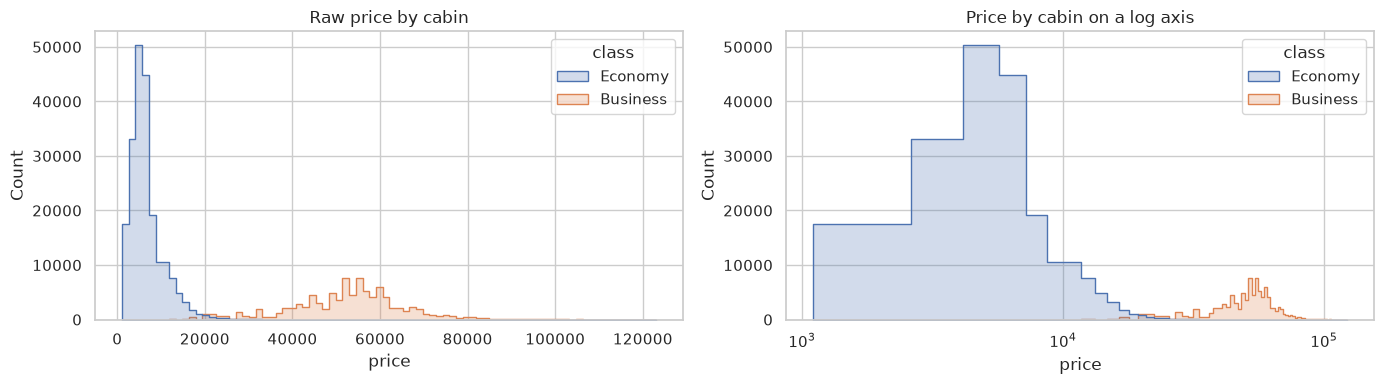

raw skew: 1.0613772532064343 log1p skew: 0.40452027498368953


,count,mean,median,std
class,,,,
Business,93487,52540.081124,53164.0,12969.314606
Economy,206666,6572.342383,5772.0,3743.519517


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax in axes:
    sns.histplot(data=df, x='price', hue='class', bins=80, element='step', ax=ax)
axes[0].set_title('Raw price by cabin')
axes[1].set_xscale('log'); axes[1].set_title('Price by cabin on a log axis')
plt.tight_layout(); plt.show()
raw_skew, log_skew = df.price.skew(), np.log1p(df.price).skew()
print('raw skew:', raw_skew, 'log1p skew:', log_skew)
cabin_stats = df.groupby('class')['price'].agg(['count', 'mean', 'median', 'std'])
display(cabin_stats)

**Target distribution — interpretation.** Economy mean fare is ₹6,572.34, while Business mean fare is ₹52,540.08, about eight times higher. Raw price skew is 1.0614; `log1p(price)` skew is 0.4045, so logging reduces asymmetry but does not make the cabin mixture a single homogeneous population. I expect MAE-oriented training to be a useful comparison because large Business residuals can dominate squared-error training, although the preferred objective must still be measured. I will retain cabin class, report both absolute and relative errors, and treat a log target as a future experiment rather than silently changing the target during these comparisons.

### 2b — Is this problem linear?

Before you can argue that you need a boosted tree ensemble, you have to know what a straight line gets you. And before you can read a correlation matrix, note the limit of the tool: **Pearson correlation measures only the *linear* part of a relationship.** A perfect U-shaped relationship has a correlation near zero. A low correlation does not mean "no relationship" — it means "no *linear* relationship", which is a much narrower claim.

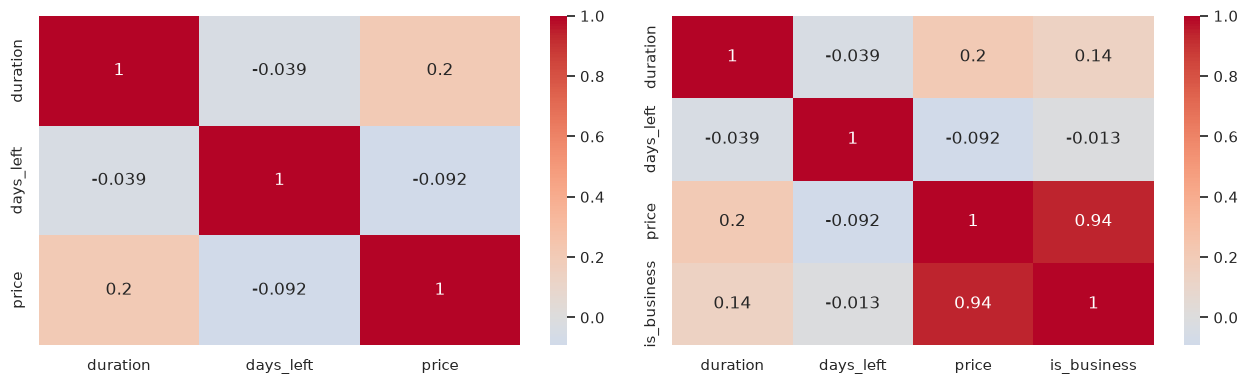

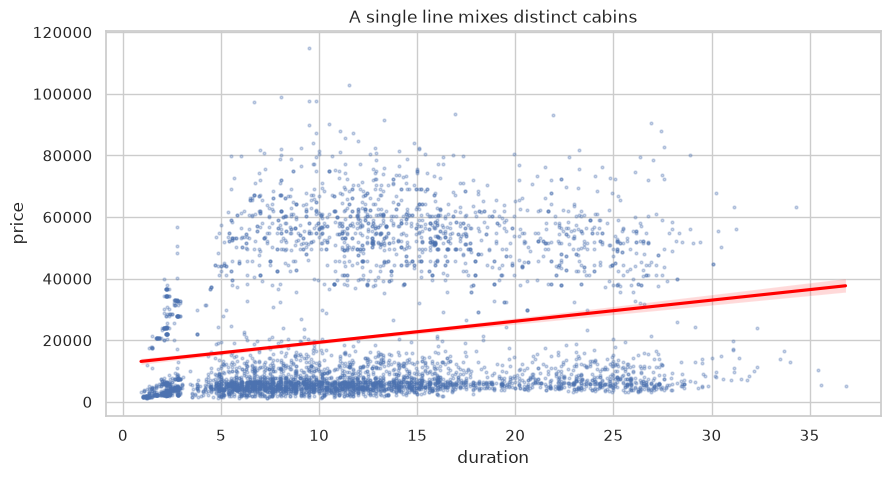

price correlations: {'duration': 0.20422236784543787, 'days_left': -0.09194853217143521, 'price': 1.0, 'is_business': 0.937860323905898}


In [35]:
num = df[['duration', 'days_left', 'price']]
tmp = num.assign(is_business=(df['class'] == 'Business').astype(int))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(num.corr(), annot=True, cmap='coolwarm', center=0, ax=axes[0])
sns.heatmap(tmp.corr(), annot=True, cmap='coolwarm', center=0, ax=axes[1])
plt.tight_layout(); plt.show()
s = df.sample(min(5000, len(df)), random_state=RANDOM_STATE)
sns.regplot(data=s, x='duration', y='price', scatter_kws={'s': 4, 'alpha': .3},
            line_kws={'color': 'red'})
plt.title('A single line mixes distinct cabins'); plt.show()
print('price correlations:', tmp.corr()['price'].to_dict())

**Linearity — interpretation.** The Business indicator has price correlation 0.9379, compared with 0.2042 for duration and −0.0919 for days left, making cabin the strongest of these individual linear associations. A single duration line averages across separated Economy and Business price bands and misses within-cabin and route-dependent structure. A weak marginal duration correlation does not prove that duration is unimportant: different cabins/routes can mask conditional associations, and Pearson correlation cannot detect every nonlinear shape. This motivates fitting an interpretable linear baseline and comparing it with trees rather than deciding from correlation alone.

### 2c — The booking curve: the one piece of this dataset with a time axis

This is the most important plot in the notebook, and it is the one Deliverable 1 never made.

`days_left` is **days until departure**. It is not a timestamp, but it *is* an ordered horizon — so if you average price at each value of `days_left`, you get a genuine **sequence**: how fare moves as departure approaches. Airlines call this the booking curve, and forecasting it is a real job.

That ordered sequence is the only thing in this dataset a time-series model like ARIMA can operate on. Section 6c comes back to it.

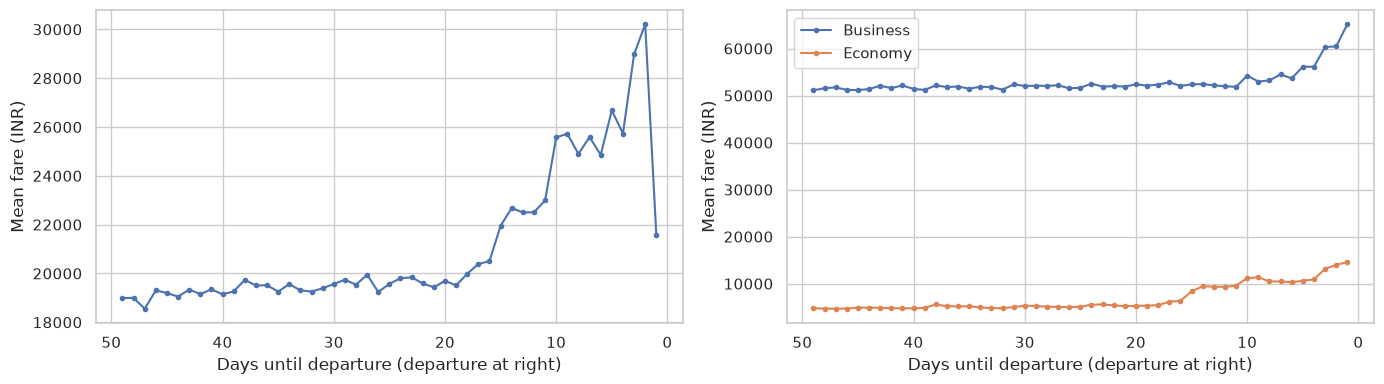

ordered horizon points: 49
mean fares at selected horizons:


,mean,median,count
days_left,,,
1,21591.867151,15163.0,1927
7,25588.367351,12990.0,5703
14,22678.002363,11389.0,6349
21,19430.494058,6111.0,6479
35,19255.652996,6158.0,6291
49,18992.971888,5949.0,6154


In [36]:
booking_curve = df.groupby('days_left')['price'].agg(['mean', 'median', 'count'])
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(booking_curve.index, booking_curve['mean'], marker='o', ms=3)
for cabin, grp in df.groupby('class'):
    c = grp.groupby('days_left')['price'].mean()
    axes[1].plot(c.index, c.values, marker='o', ms=3, label=cabin)
for ax in axes:
    ax.invert_xaxis(); ax.set_xlabel('Days until departure (departure at right)')
    ax.set_ylabel('Mean fare (INR)')
axes[1].legend(); plt.tight_layout(); plt.show()
print('ordered horizon points:', len(booking_curve))
print('mean fares at selected horizons:')
display(booking_curve.loc[[1, 7, 14, 21, 35, 49]])

**Booking curve — interpretation.** The aggregate relationship is nonlinear: mean fare is about ₹18,993 at 49 days, ₹19,430 at 21 days, ₹22,678 at 14 days and ₹25,588 at seven days. The strongest increase is roughly inside the final two to three weeks, but the final day falls to ₹21,592, so it is not a monotone countdown rule. Both cabins show near-departure changes, but the absolute levels and shapes differ, and the aggregate is also affected by which tickets appear at each horizon. A raw linear `days_left` term cannot follow that bend; horizon bins, splines or a cabin interaction could help a linear model, whereas trees can split the horizon directly. There are only 49 aggregate points, a small sample for ARIMA, and these are pooled cross-sectional horizon means rather than one flight followed through calendar time.

### 2d — Categories: counts, dominance, and encoding

In [37]:
cats = ['airline', 'source_city', 'departure_time', 'stops',
        'arrival_time', 'destination_city', 'class']
for c in cats:
    print(f'{c:20s} {df[c].nunique():3d} {sorted(df[c].unique())}')
    print(df[c].value_counts().to_dict())
display(pd.crosstab(df['airline'], df['class'], values=df.price, aggfunc='mean'))
route_price = df.groupby(['source_city', 'destination_city'])['price'].mean()
display(route_price.sort_values().head(5), route_price.sort_values().tail(5))

airline                6 ['AirAsia', 'Air_India', 'GO_FIRST', 'Indigo', 'SpiceJet', 'Vistara']
{'Vistara': 127859, 'Air_India': 80892, 'Indigo': 43120, 'GO_FIRST': 23173, 'AirAsia': 16098, 'SpiceJet': 9011}
source_city            6 ['Bangalore', 'Chennai', 'Delhi', 'Hyderabad', 'Kolkata', 'Mumbai']
{'Delhi': 61343, 'Mumbai': 60896, 'Bangalore': 52061, 'Kolkata': 46347, 'Hyderabad': 40806, 'Chennai': 38700}
departure_time         6 ['Afternoon', 'Early_Morning', 'Evening', 'Late_Night', 'Morning', 'Night']
{'Morning': 71146, 'Early_Morning': 66790, 'Evening': 65102, 'Night': 48015, 'Afternoon': 47794, 'Late_Night': 1306}
stops                  3 ['one', 'two_or_more', 'zero']
{'one': 250863, 'zero': 36004, 'two_or_more': 13286}
arrival_time           6 ['Afternoon', 'Early_Morning', 'Evening', 'Late_Night', 'Morning', 'Night']
{'Night': 91538, 'Evening': 78323, 'Morning': 62735, 'Afternoon': 38139, 'Early_Morning': 15417, 'Late_Night': 14001}
destination_city       6 ['Bangalore', 'Chen

class,Business,Economy
airline,,
AirAsia,NaN,4091.072742
Air_India,47131.039212,7313.682169
GO_FIRST,NaN,5652.007595
Indigo,NaN,5324.216303
SpiceJet,NaN,6179.278881
Vistara,55477.027777,7806.943645


source_city  destination_city
Hyderabad    Delhi               17243.945685
Delhi        Hyderabad           17347.288379
Bangalore    Delhi               17723.313972
Delhi        Bangalore           17880.216315
Mumbai       Delhi               18725.320008
Name: price, dtype: float64

source_city  destination_city
Mumbai       Bangalore           23147.873807
Bangalore    Chennai             23321.850078
             Kolkata             23500.061229
Kolkata      Chennai             23660.361040
Chennai      Bangalore           25081.850454
Name: price, dtype: float64

> **Which columns are ordered, and which are not?** This matters in Section 4 more than you would guess.
>
> - `stops` is **ordinal**: `zero < one < two_or_more`. That is a real ranking.
> - `departure_time` / `arrival_time` are **ordinal**: `Early_Morning < Morning < Afternoon < Evening < Night < Late_Night` — they are a clock.
> - `airline`, `source_city`, `destination_city` are **nominal**. There is no sense in which Vistara > SpiceJet.
>
> Deliverable 1 used `LabelEncoder` on all seven, which assigns integers **alphabetically**. For `stops` that gives `one=0, two_or_more=1, zero=2` — telling the model a direct flight ranks *above* a two-stop flight. Not just arbitrary: backwards.
>
> A tree can route around this by spending extra splits to separate the categories again, so the cost shows up as wasted capacity. **A linear model cannot route around it at all** — it gets one coefficient per column and is forced to assume evenly-spaced, ordered effects. Section 4 shows you exactly how much that costs.

### 2e — EDA summary: four decisions

| Observation | Therefore, when I model, I will... |
|---|---|
| Price mixes lower-priced Economy and higher-priced Business fares; logging changes skew but does not remove the two populations. | Keep cabin class, compare MAE and RMSE, and evaluate cabin-level errors before deployment rather than assuming one loss treats both cabins equally. |
| Cabin class carries the strongest individual linear signal among the inspected features. | Include `class` explicitly and assert that preprocessing covers every intended feature. Treat cabin comparisons as associations, not causal effects. |
| The booking horizon has a sharp near-departure change rather than one constant slope. | Compare trees with linear baselines; a future linear extension could use horizon buckets or splines fitted inside the pipeline. |
| Stops have an order; the provided time bands have a clock order; airlines and cities have no ranking. | Use the specified ordinal orders for stops/time and one-hot encoding for nominal features. Time wraps around midnight, so this ordinal representation is an approximation, especially for a linear model. |

The EDA uses the available dataset for this instructional exercise; this is not an untouched prospective evaluation. For deployment, freeze these decisions and evaluate on newly collected, dated data.

---
# Section 3 — Data leakage

**Goal:** find the three places the Deliverable 1 setup let information leak, fix each one, and **measure what each was actually worth** rather than assuming.

> **Leakage** is when information reaches the model at training time that will not be available at prediction time.

It is not exotic. It is the default result of writing code in the order that feels natural — "clean everything, then split" — because every transform fitted before the split has already seen the test set.

Deliverable 1 had three leaks:

| # | Leak | Where |
|---|---|---|
| 1 | **The row counter.** `Unnamed: 0` was never dropped, so it sat in `X`. A future flight has no row number. | D1 §3a |
| 2 | **Duplicate rows across the split.** Once the unique counter is removed, this dataset contains repeated rows; copies can land in train *and* test, so the model is graded on rows it memorised. | D1 §3c |
| 3 | **Encoders fitted on the full dataset.** `df[col] = le.fit_transform(df[col])` ran in §3b, *before* the split in §3c. | D1 §3b |

**Be precise about leak 3's severity**, because overstating it is its own error. A plain `LabelEncoder` on complete categorical columns learns a list of category *names* — it learns nothing about price, so the practical damage is small. It is still **wrong as a habit**, because the identical code shape is severe the moment the transform learns something numeric:

- a `StandardScaler` fitted pre-split leaks the test set's mean and variance
- a **target encoder** fitted pre-split leaks the test set's *prices* directly
- an imputer fitted pre-split leaks the test distribution

You will not remember which transforms are safe at 2am. **Fit every transform inside the split, always.** That is what `Pipeline` is for.

### 3a — Reproduce the Deliverable 1 baseline (given)

Given to you complete, so every member starts from the identical reference number. Read it and match each line to a section of the old notebook.

In [38]:
def deliverable1_baseline(path, random_state=RANDOM_STATE):
    """Reproduce Deliverable 1 exactly -- leaks and all.

      D1 S1  : read_csv
      D1 S2a : dropna
      D1 S3a : drop 'flight'        <- but NOT the row counter
      D1 S3b : LabelEncoder on the FULL frame, before the split   <- leak 3
      D1 S3c : X = everything except price; 80/20 split           <- dupes straddle it
      D1 S4  : XGBRegressor, same hyperparameters
    """
    from sklearn.preprocessing import LabelEncoder

    frame = pd.read_csv(path)
    frame.columns = [c.strip().lower().replace(' ', '_') for c in frame.columns]
    frame = frame.dropna().drop(columns=['flight'])

    for col in ['airline', 'source_city', 'departure_time', 'stops',
                'arrival_time', 'destination_city', 'class']:
        # Fitted on 100% of rows -- including the ones we will call "unseen".
        frame[col] = LabelEncoder().fit_transform(frame[col])

    X = frame.drop(columns=['price'])
    y = frame['price']
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, random_state=random_state)

    model = XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.1,
                         subsample=0.8, colsample_bytree=0.8,
                         random_state=random_state, n_jobs=4)
    model.fit(X_tr, y_tr)
    return model, X_tr, X_te, y_tr, y_te, model.predict(X_te)


t0 = time.time()
d1_model, d1_X_tr, d1_X_te, d1_y_tr, d1_y_te, d1_pred = deliverable1_baseline(DATA_PATH)
print(f'trained in {time.time() - t0:.1f}s')
print('features the D1 model was given:', d1_X_tr.columns.tolist())

record(regression_report(d1_y_te, d1_pred, 'D1 baseline (3 leaks)'))

trained in 1.7s
features the D1 model was given: ['unnamed:_0', 'airline', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class', 'duration', 'days_left']


,MAE,RMSE,R2,MAPE%
model,,,,
D1 baseline (3 leaks),1926.8089,3379.2592,0.9778,14.4221


In [39]:
importance = pd.Series(d1_model.feature_importances_, index=d1_X_tr.columns).sort_values(ascending=False)
display(importance)
raw_sorted = raw.rename(columns=lambda c: c.strip().lower().replace(' ', '_'))
counter_cols = [c for c in raw_sorted if c.startswith('unnamed')]
assert len(counter_cols) == 1
counter_col = counter_cols[0]
display(raw_sorted.groupby('class')[counter_col].agg(['min', 'max', 'count']))

class               0.965582
unnamed:_0          0.010665
stops               0.005613
duration            0.004672
airline             0.004295
days_left           0.003148
source_city         0.002224
destination_city    0.001889
arrival_time        0.001189
departure_time      0.000722
dtype: float32

,min,max,count
class,,,
Business,206666,300152,93487
Economy,0,206665,206666


### 3b — Remove the leaks, one at a time

One change per step, so each result is **attributable**. Change three things at once and you learn nothing about any of them.

In [40]:
from sklearn.preprocessing import LabelEncoder

def fit_legacy(frame, label):
    encoded = frame.copy()
    for col in cats:
        encoded[col] = LabelEncoder().fit_transform(encoded[col])
    features, target = encoded.drop(columns='price'), encoded.price
    tr, te, ytr, yte = train_test_split(features, target, test_size=.2, random_state=RANDOM_STATE)
    model = XGBRegressor(n_estimators=300, max_depth=6, learning_rate=.1,
                         subsample=.8, colsample_bytree=.8, random_state=RANDOM_STATE, n_jobs=4)
    t0 = time.perf_counter(); model.fit(tr, ytr)
    result = regression_report(yte, model.predict(te), label)
    result['fit_seconds'] = time.perf_counter() - t0
    display(record(result))
    return model

frame = df.dropna().drop(columns='flight')
no_counter_model = fit_legacy(frame, 'no row counter')

,MAE,RMSE,R2,MAPE%,fit_seconds
model,,,,,
D1 baseline (3 leaks),1926.8089,3379.2592,0.9778,14.4221,NaN
no row counter,2096.7662,3665.6117,0.9739,14.9389,1.4738


In [41]:
# Remove duplicates on the actual model columns, excluding the unique row counter
# and flight identifier; otherwise repeated feature/target rows can survive.
deduped = frame.drop_duplicates().reset_index(drop=True)
print('duplicate model rows removed:', len(frame) - len(deduped))
no_dupes_model = fit_legacy(deduped, 'no counter + deduped')
# Retain flight for the explicit transformer coverage assertion, while using
# exactly the same deduplication definition as the preceding ablation.
model_cols = [c for c in df.columns if c != 'flight']
clean = df.dropna().drop_duplicates(subset=model_cols).reset_index(drop=True)
assert len(clean) == len(deduped)

duplicate model rows removed: 2213


,MAE,RMSE,R2,MAPE%,fit_seconds
model,,,,,
D1 baseline (3 leaks),1926.8089,3379.2592,0.9778,14.4221,NaN
no row counter,2096.7662,3665.6117,0.9739,14.9389,1.4738
no counter + deduped,2108.4547,3648.2677,0.9741,15.2509,1.4115


### 3c — Step 3: a `Pipeline`, so preprocessing is fitted within each training split

A **`Pipeline`** is a list of `(name, transform)` steps ending in a model, wrapped to behave as one estimator. What matters is what `.fit()` does:

```
pipe.fit(X_train, y_train)
   -> every transform learns ONLY from X_train
pipe.predict(X_test)
   -> every transform APPLIES what it learned; it never re-learns from X_test
```

You cannot accidentally fit on the test set, because you never call `.fit` on a transform yourself. And this becomes essential rather than merely tidy in Section 4, where we cross-validate over many `alpha` values: without a pipeline, the scaler would be refitted on each fold's test data and every number would be slightly wrong.

A **`ColumnTransformer`** routes different columns to different transforms:

```python
ColumnTransformer([
    ('nom', OneHotEncoder(handle_unknown='ignore'), nominal_cols),
    ('ord', OrdinalEncoder(categories=[...]),       ordinal_cols),
    ('num', StandardScaler(),                       numeric_cols),
])
```

`handle_unknown='ignore'` is the production-mindset flag: if an unseen category appears at prediction time (a new airline launches), encode it as all-zeros instead of crashing.

In [42]:
NOMINAL = ['airline', 'source_city', 'destination_city', 'class']
ORDINAL = ['stops', 'departure_time', 'arrival_time']
NUMERIC = ['duration', 'days_left']
STOPS_ORDER = ['zero', 'one', 'two_or_more']
TIME_ORDER = ['Early_Morning', 'Morning', 'Afternoon', 'Evening', 'Night', 'Late_Night']

> **⚠️ `remainder='drop'` is a footgun, and this is the moment to respect it.** The `ColumnTransformer` you are about to build **silently discards** every column you did not put in a group. No error. No warning.
>
> On this dataset that mistake is expensive in a very specific way: `class` is the strongest single predictor here, worth roughly **0.98 R² with it versus 0.19 without**. Forget it and your model is near-useless — and nothing in the output will say so. You will just see a bad score and start blaming your hyperparameters.
>
> So do not verify coverage by eye. Make the computer do it.

In [43]:
assigned = set(NOMINAL) | set(ORDINAL) | set(NUMERIC)
features = set(clean.columns) - {'price'}
dropped = features - assigned
print('assigned:', sorted(assigned)); print('dropped:', sorted(dropped))
assert dropped == {'flight'}, f'unexpectedly dropping: {dropped}'
assert len(NOMINAL + ORDINAL + NUMERIC) == len(assigned)
print('coverage OK')

assigned: ['airline', 'arrival_time', 'class', 'days_left', 'departure_time', 'destination_city', 'duration', 'source_city', 'stops']
dropped: ['flight']
coverage OK


In [44]:
prep_tree = ColumnTransformer([
    ('nom', OneHotEncoder(handle_unknown='ignore', sparse_output=False), NOMINAL),
    ('ord', OrdinalEncoder(categories=[STOPS_ORDER, TIME_ORDER, TIME_ORDER],
                           handle_unknown='use_encoded_value', unknown_value=-1), ORDINAL),
    ('num', 'passthrough', NUMERIC),
], remainder='drop')
# Drop one reference category per nominal feature to avoid redundant coefficients.
# Scale ALL encoded predictors, including ordinal columns, inside each fit.
prep_linear = Pipeline([
    ('encode', ColumnTransformer([
        ('nom', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), NOMINAL),
        ('ord', OrdinalEncoder(categories=[STOPS_ORDER, TIME_ORDER, TIME_ORDER],
                               handle_unknown='use_encoded_value', unknown_value=-1), ORDINAL),
        ('num', 'passthrough', NUMERIC),
    ], remainder='drop')),
    ('scale', StandardScaler()),
])

In [45]:
X, y = clean.drop(columns='price'), clean.price
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=RANDOM_STATE)
print(f'{len(X_train):,} train / {len(X_test):,} test')
# This split is identical to Step 2: only preprocessing changes here.
xgb_pipe = Pipeline([('prep', clone(prep_tree)), ('model', XGBRegressor(
    n_estimators=300, max_depth=6, learning_rate=.1, subsample=.8,
    colsample_bytree=.8, random_state=RANDOM_STATE, n_jobs=4))])
t0 = time.perf_counter(); xgb_pipe.fit(X_train, y_train)
honest = regression_report(y_test, xgb_pipe.predict(X_test), 'XGBoost (honest, full training)')
honest['fit_seconds'] = time.perf_counter() - t0
display(record(honest))
# Same sample for every Sections 4–6 ticket model, never sampled from the test set.
X_fit = X_train.sample(min(80000, len(X_train)), random_state=RANDOM_STATE)
y_fit = y_train.loc[X_fit.index]
print('comparison training sample:', len(X_fit), '| shared test:', len(X_test))

238,352 train / 59,588 test


,MAE,RMSE,R2,MAPE%,fit_seconds
model,,,,,
D1 baseline (3 leaks),1926.8089,3379.2592,0.9778,14.4221,NaN
no row counter,2096.7662,3665.6117,0.9739,14.9389,1.4738
no counter + deduped,2108.4547,3648.2677,0.9741,15.2509,1.4115
"XGBoost (honest, full training)",1990.2113,3500.5308,0.9761,14.3995,1.9343


comparison training sample: 80000 | shared test: 59588


### 3d — Target leakage: the expensive kind

The three leaks above were about *process*. This one is about a *feature*, and it is the one that ends projects.

Here is a feature a well-meaning teammate will propose:

```python
df['price_per_hour'] = df['price'] / df['duration']
```

It is intuitive, it is a real industry unit (yield per block hour), and adding it will take your R² to something like 0.999.

**It is computed from the target.** At prediction time you do not have `price` — predicting it is the whole job. The feature can only exist for rows where you already know the answer.

**Target leakage** is the most expensive mistake in applied ML precisely because it does not look like a bug. Nothing crashes, no warning fires, your metrics improve, and the model is worthless.

> **The test, five seconds per feature:** *"at the moment I need a prediction, do I have this value?"* If the honest answer is "no, I would need the price first" — delete it.

In [46]:
leaky = clean.assign(price_per_hour=clean.price / clean.duration)
Xl = leaky[['price_per_hour', 'duration', 'days_left']]
Xl_tr, Xl_te, yl_tr, yl_te = train_test_split(Xl, leaky.price, test_size=.2, random_state=RANDOM_STATE)
m = XGBRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=4)
m.fit(Xl_tr, yl_tr)
leak_report = regression_report(yl_te, m.predict(Xl_te), 'TARGET LEAK — INVALID')
print(leak_report)
# Deliberately excluded from SCOREBOARD; production features never contain this.
del leaky, Xl, Xl_tr, Xl_te, m
assert 'price_per_hour' not in X_train.columns

{'model': 'TARGET LEAK — INVALID', 'MAE': 239.55441520687333, 'RMSE': 478.49107092954705, 'R2': 0.9995542433182922, 'MAPE%': 1.7683623945273335}


### 3e — One split is an anecdote

Even leak-free, our score rests on **one** arbitrary 80/20 split. Change `random_state` and the number moves. How much is measurable, and you should measure it before quoting anything.

**K-fold cross-validation** splits the data into k parts, trains k times, validates on each part once. The **mean** is a better estimate; the **standard deviation** tells you how much your single number could have been luck.

> Quote scores as **mean ± std**. A model at 0.95 ± 0.002 and one at 0.95 ± 0.04 are not the same model, and the second is not ready to ship.

In [47]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
# CV uses training rows ONLY; the shared test set stays outside every fit.
scores = cross_validate(xgb_pipe, X_fit, y_fit, cv=cv,
                        scoring=['r2', 'neg_mean_absolute_error'],
                        n_jobs=1, return_train_score=True)
cv_summary = pd.DataFrame({
    'validation_R2': scores['test_r2'], 'training_R2': scores['train_r2'],
    'validation_MAE': -scores['test_neg_mean_absolute_error'],
})
display(cv_summary)
display(cv_summary.agg(['mean', 'std', 'min', 'max']))
print('CV sample:', len(X_fit), '; each fold trains on 80% of that sample.')

,validation_R2,training_R2,validation_MAE
0,0.974738,0.980199,2052.390137
1,0.974850,0.980228,2027.539917
2,0.976701,0.979619,1977.440308
3,0.975977,0.979824,2048.893555
4,0.975339,0.979826,2035.594238


,validation_R2,training_R2,validation_MAE
mean,0.975521,0.979939,2028.371631
std,0.000821,0.000264,30.186485
min,0.974738,0.979619,1977.440308
max,0.976701,0.980228,2052.390137


CV sample: 80000 ; each fold trains on 80% of that sample.


**Leak ledger — interpretation.** The D1 reproduction scored R² 0.9778; removing the row counter reduced it to 0.9739, the largest downward step (about 0.0039). The counter ranked second in gain importance and separated cabin ranges in the sorted file, so it carried an artificial ordering signal unavailable for a future ticket. Removing 2,213 duplicate model rows produced R² 0.9741, a small increase rather than the expected collapse; deduplication also changes which observations enter each split, so this is a measured ablation rather than an exact causal estimate. The full-training clean pipeline scored R² 0.9761 and MAE ₹1,990, slightly worse than D1 overall; the last step also changes the encoding scheme, so its improvement cannot be attributed only to fitting encoders inside the split. Five-fold CV on 80,000 training-only rows gave validation R² 0.9755 ± 0.0008 and MAE ₹2,028 ± ₹30, versus mean training R² 0.9799, suggesting a modest generalization gap. I would report the honest score and its evaluation setup, with CV variability as context; this random-split estimate is not evidence of accuracy on future American Airlines flights, and fold standard deviation is not a confidence interval.

---
# Section 4 — Lasso vs Ridge: two ways to regularise a linear model

**Goal:** understand what regularisation *is*, what the L1 and L2 penalties do differently, and why that difference is useful rather than academic.

### Why fit a linear model at all, when you already have XGBoost?

Three reasons, and none of them is "it might win":

1. **It is a reference point.** "XGBoost got R² 0.95" is meaningless until you know a linear model gets 0.90 — or 0.55.
2. **It is interpretable.** A linear model hands you one coefficient per feature: *this airline adds ₹1,800 to the fare, all else equal.* No tree ensemble gives you a sentence like that, and that sentence is often what a client actually wants.
3. **Lasso does feature selection for free**, which is the real payoff in this section.

### The shared objective

Both models minimise squared error **plus** a penalty on the size of the coefficients:

```
Ridge  (L2):   minimise   ||y - Xw||²  +  α · Σ wⱼ²
Lasso  (L1):   minimise   ||y - Xw||²  +  α · Σ |wⱼ|
```

The only difference is `wⱼ²` versus `|wⱼ|`. That one change produces completely different behaviour:

| | **Ridge (L2)** | **Lasso (L1)** |
|---|---|---|
| Penalty | sum of **squared** coefficients | sum of **absolute** coefficients |
| Shrinks coefficients | yes, smoothly toward zero | yes |
| Sets them to **exactly zero** | essentially never | **yes** — that is the point |
| Correlated features | **shares** the weight between them | **picks one**, zeroes the rest |
| Gives you | a stable model using every feature | a **sparse** model, i.e. feature selection |
| Closed-form solution | yes | no — needs iterative optimisation |
| Reach for it when | you believe most features matter a little | you believe few features matter a lot |

### Why does L1 produce exact zeros and L2 does not?

The geometric picture is the one worth remembering. Think of the penalty as a budget constraining where `w` can live:

- The **L2** budget `Σwⱼ² ≤ t` is a **circle** (sphere). Smooth, no corners.
- The **L1** budget `Σ|wⱼ| ≤ t` is a **diamond**, and its corners sit **on the axes**.

The solution lands where the error contours first touch that region. A diamond's corners stick out, so contours tend to touch at a corner — and a corner *is* a point where some coefficient equals exactly zero. A circle has no corners, so the touch point almost always has every coefficient slightly non-zero.

> **⚠️ Scaling is mandatory here, not optional.** Both penalties sum over coefficient *magnitudes*, and a coefficient's magnitude depends on its feature's units. `duration` in hours (0–50) and `days_left` in days (1–49) are comparable, but if one were in minutes its coefficient would be ~60× smaller and the penalty would barely touch it. **Unscaled features mean the penalty silently punishes some features more than others.** This is why `prep_linear` has a `StandardScaler` and `prep_tree` does not — and why both live inside a `Pipeline`, so the scaler is fitted per fold.

In [48]:
fitted = {}
def fit_compare(name, estimator, prep):
    pipe = Pipeline([('prep', clone(prep)), ('model', estimator)])
    t0 = time.perf_counter(); pipe.fit(X_fit, y_fit)
    elapsed = time.perf_counter() - t0
    rep = regression_report(y_test, pipe.predict(X_test), name)
    rep.update(fit_seconds=elapsed, training_rows=len(X_fit))
    fitted[name] = pipe
    display(record(rep))
    return pipe

for name, est in {
    'LinearRegression': LinearRegression(),
    'Ridge (alpha=1)': Ridge(alpha=1),
    'Lasso (alpha=1)': Lasso(alpha=1, max_iter=20000),
}.items():
    fit_compare(name, est, prep_linear)

,MAE,RMSE,R2,MAPE%,fit_seconds,training_rows
model,,,,,,
D1 baseline (3 leaks),1926.8089,3379.2592,0.9778,14.4221,NaN,NaN
no row counter,2096.7662,3665.6117,0.9739,14.9389,1.4738,NaN
no counter + deduped,2108.4547,3648.2677,0.9741,15.2509,1.4115,NaN
"XGBoost (honest, full training)",1990.2113,3500.5308,0.9761,14.3995,1.9343,NaN
LinearRegression,4516.6450,6831.7500,0.9091,42.7393,0.1021,80000.0


,MAE,RMSE,R2,MAPE%,fit_seconds,training_rows
model,,,,,,
D1 baseline (3 leaks),1926.8089,3379.2592,0.9778,14.4221,NaN,NaN
no row counter,2096.7662,3665.6117,0.9739,14.9389,1.4738,NaN
no counter + deduped,2108.4547,3648.2677,0.9741,15.2509,1.4115,NaN
"XGBoost (honest, full training)",1990.2113,3500.5308,0.9761,14.3995,1.9343,NaN
LinearRegression,4516.6450,6831.7500,0.9091,42.7393,0.1021,80000.0
Ridge (alpha=1),4516.6388,6831.7457,0.9091,42.7390,0.1202,80000.0


,MAE,RMSE,R2,MAPE%,fit_seconds,training_rows
model,,,,,,
D1 baseline (3 leaks),1926.8089,3379.2592,0.9778,14.4221,NaN,NaN
no row counter,2096.7662,3665.6117,0.9739,14.9389,1.4738,NaN
no counter + deduped,2108.4547,3648.2677,0.9741,15.2509,1.4115,NaN
"XGBoost (honest, full training)",1990.2113,3500.5308,0.9761,14.3995,1.9343,NaN
LinearRegression,4516.6450,6831.7500,0.9091,42.7393,0.1021,80000.0
Ridge (alpha=1),4516.6388,6831.7457,0.9091,42.7390,0.1202,80000.0
Lasso (alpha=1),4516.1330,6831.7512,0.9091,42.7238,0.5842,80000.0


### 4a — What `alpha` actually does

`alpha` is the **regularisation strength** — how much you charge the model for large coefficients.

- `alpha → 0`: no penalty. The model fits the training data as hard as it can. **High variance**, overfits.
- `alpha → ∞`: the penalty dominates. All coefficients are crushed toward zero and the model predicts roughly a constant. **High bias**, underfits.

Somewhere in between is the right value, and you find it by validation, not by taste. This is the **bias–variance tradeoff** with a dial on it.

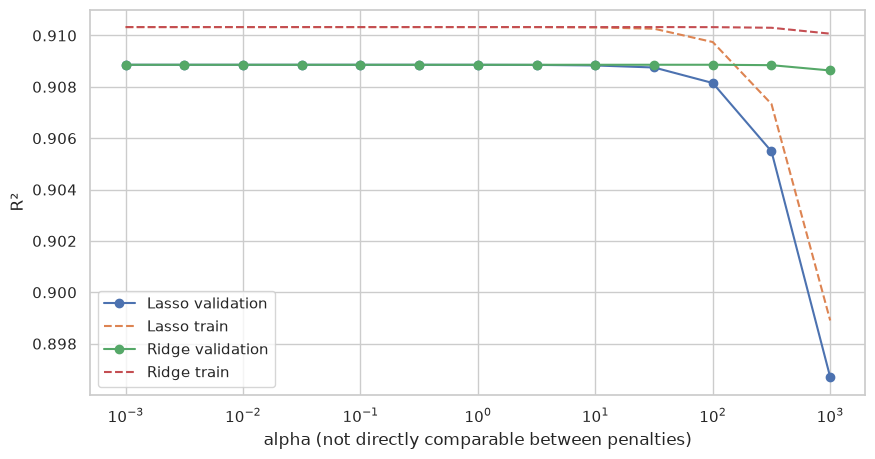

Ridge best inner-validation alpha: 100.0


,MAE,RMSE,R2,MAPE%,fit_seconds,training_rows
model,,,,,,
D1 baseline (3 leaks),1926.8089,3379.2592,0.9778,14.4221,NaN,NaN
no row counter,2096.7662,3665.6117,0.9739,14.9389,1.4738,NaN
no counter + deduped,2108.4547,3648.2677,0.9741,15.2509,1.4115,NaN
"XGBoost (honest, full training)",1990.2113,3500.5308,0.9761,14.3995,1.9343,NaN
LinearRegression,4516.6450,6831.7500,0.9091,42.7393,0.1021,80000.0
Ridge (alpha=1),4516.6388,6831.7457,0.9091,42.7390,0.1202,80000.0
Lasso (alpha=1),4516.1330,6831.7512,0.9091,42.7238,0.5842,80000.0
Ridge (validation selected),4516.1011,6831.3875,0.9091,42.7065,0.0942,80000.0


Lasso best inner-validation alpha: 0.001


,MAE,RMSE,R2,MAPE%,fit_seconds,training_rows
model,,,,,,
D1 baseline (3 leaks),1926.8089,3379.2592,0.9778,14.4221,NaN,NaN
no row counter,2096.7662,3665.6117,0.9739,14.9389,1.4738,NaN
no counter + deduped,2108.4547,3648.2677,0.9741,15.2509,1.4115,NaN
"XGBoost (honest, full training)",1990.2113,3500.5308,0.9761,14.3995,1.9343,NaN
LinearRegression,4516.6450,6831.7500,0.9091,42.7393,0.1021,80000.0
Ridge (alpha=1),4516.6388,6831.7457,0.9091,42.7390,0.1202,80000.0
Lasso (alpha=1),4516.1330,6831.7512,0.9091,42.7238,0.5842,80000.0
Ridge (validation selected),4516.1011,6831.3875,0.9091,42.7065,0.0942,80000.0
Lasso (validation selected),4516.6445,6831.7500,0.9091,42.7393,0.5181,80000.0


,alpha,model,train_r2,validation_r2
0,0.001000,Ridge,0.910328,0.908860
1,0.001000,Lasso,0.910328,0.908860
2,0.003162,Ridge,0.910328,0.908860
3,0.003162,Lasso,0.910328,0.908860
4,0.010000,Ridge,0.910328,0.908860
5,0.010000,Lasso,0.910328,0.908860
6,0.031623,Ridge,0.910328,0.908860
7,0.031623,Lasso,0.910328,0.908860
8,0.100000,Ridge,0.910328,0.908860
9,0.100000,Lasso,0.910328,0.908860


In [49]:
# Choose alpha on an INNER validation set, not on the final test set.
Xa, Xv, ya, yv = train_test_split(X_fit, y_fit, test_size=.2, random_state=RANDOM_STATE)
alphas = np.logspace(-3, 3, 13)
rows = []
for a in alphas:
    for name, est in [('Ridge', Ridge(alpha=a)), ('Lasso', Lasso(alpha=a, max_iter=20000))]:
        pipe = Pipeline([('prep', clone(prep_linear)), ('model', est)])
        pipe.fit(Xa, ya)
        rows.append({'alpha': a, 'model': name, 'train_r2': pipe.score(Xa, ya),
                     'validation_r2': pipe.score(Xv, yv)})
sweep = pd.DataFrame(rows)
for name, grp in sweep.groupby('model'):
    plt.semilogx(grp.alpha, grp.validation_r2, marker='o', label=f'{name} validation')
    plt.semilogx(grp.alpha, grp.train_r2, ls='--', label=f'{name} train')
plt.xlabel('alpha (not directly comparable between penalties)'); plt.ylabel('R²')
plt.legend(); plt.show()
best_alphas = {}
for name in ['Ridge', 'Lasso']:
    grp = sweep[sweep.model == name]
    best_alphas[name] = float(grp.loc[grp.validation_r2.idxmax(), 'alpha'])
    print(name, 'best inner-validation alpha:', best_alphas[name])
    est = Ridge(alpha=best_alphas[name]) if name == 'Ridge' else Lasso(alpha=best_alphas[name], max_iter=20000)
    fit_compare(name + ' (validation selected)', est, prep_linear)
display(sweep)

In [50]:
lasso_pipe = fit_compare('Lasso (alpha=100, sparsity)', Lasso(alpha=100, max_iter=20000), prep_linear)
names = lasso_pipe.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(lasso_pipe.named_steps['model'].coef_, index=names)
print('features kept:', int((coefs != 0).sum()), 'zeroed:', int((coefs == 0).sum()))
print('zeroed features:', coefs[coefs == 0].index.tolist())
display(coefs[coefs != 0].sort_values(key=abs, ascending=False).head(15))
ridge100 = Pipeline([('prep', clone(prep_linear)), ('model', Ridge(alpha=100))]).fit(X_fit, y_fit)
print('Ridge exact zeros:', int((ridge100.named_steps['model'].coef_ == 0).sum()))
# Undo scaling to interpret coefficients in original encoded units. Nominal
# effects are differences from the dropped reference, not causal fare changes.
unit_coefs = coefs / lasso_pipe.named_steps['prep'].named_steps['scale'].scale_
for name in coefs.abs().nlargest(3).index:
    print(f'{name}: one original encoded unit corresponds to {unit_coefs[name]:,.2f} INR, holding other encoded predictors fixed.')

,MAE,RMSE,R2,MAPE%,fit_seconds,training_rows
model,,,,,,
D1 baseline (3 leaks),1926.8089,3379.2592,0.9778,14.4221,NaN,NaN
no row counter,2096.7662,3665.6117,0.9739,14.9389,1.4738,NaN
no counter + deduped,2108.4547,3648.2677,0.9741,15.2509,1.4115,NaN
"XGBoost (honest, full training)",1990.2113,3500.5308,0.9761,14.3995,1.9343,NaN
LinearRegression,4516.6450,6831.7500,0.9091,42.7393,0.1021,80000.0
Ridge (alpha=1),4516.6388,6831.7457,0.9091,42.7390,0.1202,80000.0
Lasso (alpha=1),4516.1330,6831.7512,0.9091,42.7238,0.5842,80000.0
Ridge (validation selected),4516.1011,6831.3875,0.9091,42.7065,0.0942,80000.0
Lasso (validation selected),4516.6445,6831.7500,0.9091,42.7393,0.5181,80000.0


features kept: 18 zeroed: 3
zeroed features: ['nom__source_city_Chennai', 'nom__source_city_Mumbai', 'nom__destination_city_Chennai']


nom__class_Economy                -20894.916637
ord__stops                          2120.336198
num__days_left                     -1656.836681
nom__airline_Vistara                1526.185337
nom__source_city_Kolkata             506.299847
nom__destination_city_Kolkata        485.810443
num__duration                        479.041337
nom__destination_city_Delhi         -451.261348
nom__source_city_Delhi              -448.824496
nom__destination_city_Hyderabad     -448.250685
nom__source_city_Hyderabad          -407.609329
nom__airline_Air_India              -325.844461
ord__arrival_time                    323.752982
nom__airline_Indigo                  254.484368
nom__airline_GO_FIRST                 80.833025
dtype: float64

Ridge exact zeros: 0
nom__class_Economy: one original encoded unit corresponds to -45,072.15 INR, holding other encoded predictors fixed.
ord__stops: one original encoded unit corresponds to 5,362.12 INR, holding other encoded predictors fixed.
num__days_left: one original encoded unit corresponds to -122.33 INR, holding other encoded predictors fixed.


In [51]:
for ratio in [.1, .5, .9]:
    fit_compare(f'ElasticNet (l1_ratio={ratio})',
                ElasticNet(alpha=1, l1_ratio=ratio, max_iter=20000), prep_linear)

,MAE,RMSE,R2,MAPE%,fit_seconds,training_rows
model,,,,,,
D1 baseline (3 leaks),1926.8089,3379.2592,0.9778,14.4221,NaN,NaN
no row counter,2096.7662,3665.6117,0.9739,14.9389,1.4738,NaN
no counter + deduped,2108.4547,3648.2677,0.9741,15.2509,1.4115,NaN
"XGBoost (honest, full training)",1990.2113,3500.5308,0.9761,14.3995,1.9343,NaN
LinearRegression,4516.6450,6831.7500,0.9091,42.7393,0.1021,80000.0
Ridge (alpha=1),4516.6388,6831.7457,0.9091,42.7390,0.1202,80000.0
Lasso (alpha=1),4516.1330,6831.7512,0.9091,42.7238,0.5842,80000.0
Ridge (validation selected),4516.1011,6831.3875,0.9091,42.7065,0.0942,80000.0
Lasso (validation selected),4516.6445,6831.7500,0.9091,42.7393,0.5181,80000.0


,MAE,RMSE,R2,MAPE%,fit_seconds,training_rows
model,,,,,,
D1 baseline (3 leaks),1926.8089,3379.2592,0.9778,14.4221,NaN,NaN
no row counter,2096.7662,3665.6117,0.9739,14.9389,1.4738,NaN
no counter + deduped,2108.4547,3648.2677,0.9741,15.2509,1.4115,NaN
"XGBoost (honest, full training)",1990.2113,3500.5308,0.9761,14.3995,1.9343,NaN
LinearRegression,4516.6450,6831.7500,0.9091,42.7393,0.1021,80000.0
Ridge (alpha=1),4516.6388,6831.7457,0.9091,42.7390,0.1202,80000.0
Lasso (alpha=1),4516.1330,6831.7512,0.9091,42.7238,0.5842,80000.0
Ridge (validation selected),4516.1011,6831.3875,0.9091,42.7065,0.0942,80000.0
Lasso (validation selected),4516.6445,6831.7500,0.9091,42.7393,0.5181,80000.0


,MAE,RMSE,R2,MAPE%,fit_seconds,training_rows
model,,,,,,
D1 baseline (3 leaks),1926.8089,3379.2592,0.9778,14.4221,NaN,NaN
no row counter,2096.7662,3665.6117,0.9739,14.9389,1.4738,NaN
no counter + deduped,2108.4547,3648.2677,0.9741,15.2509,1.4115,NaN
"XGBoost (honest, full training)",1990.2113,3500.5308,0.9761,14.3995,1.9343,NaN
LinearRegression,4516.6450,6831.7500,0.9091,42.7393,0.1021,80000.0
Ridge (alpha=1),4516.6388,6831.7457,0.9091,42.7390,0.1202,80000.0
Lasso (alpha=1),4516.1330,6831.7512,0.9091,42.7238,0.5842,80000.0
Ridge (validation selected),4516.1011,6831.3875,0.9091,42.7065,0.0942,80000.0
Lasso (validation selected),4516.6445,6831.7500,0.9091,42.7393,0.5181,80000.0


**Lasso vs Ridge — verdict.** Inner-validation R² selected Ridge alpha 100 and Lasso alpha 0.001; on the shared test split both scored about 0.9091 R², with Ridge marginally better and a difference too small to matter operationally. The separate Lasso alpha-100 sparsity illustration removed three of 21 encoded predictors: source Chennai, source Mumbai and destination Chennai, while Ridge alpha 100 removed exactly zero. Removing those incremental city terms is plausible given the dominance of cabin and other correlated predictors, but it does not prove that these cities have no effect; EDA route averages also mix cabin composition. Ordinary least squares had essentially the same test R² as the regularized models, so regularization did not rescue this relatively low-dimensional, data-rich linear problem. For a PM who prioritizes explanation I would hand over Ridge, explaining the tradeoff against nonlinear tree fits and the conditional, non-causal nature of coefficients. In the Lasso illustration, Economy predicts about ₹45,072 less than the Business reference, one stop-code increment adds about ₹5,362, and one additional day until departure subtracts about ₹122, holding other encoded predictors fixed. The stop and horizon effects are the linear model's constant-slope assumptions, not universal fare rules; the alpha sweep shows Lasso degrading faster as its own penalty increases, and Ridge/Lasso alpha scales must not be compared directly.

At alpha 1, none of the three tested ElasticNet mixing ratios beat the plain linear/Ridge/Lasso baselines; this is not evidence that ElasticNet can never help, since its penalty strength was not tuned.

---
# Section 5 — Loss functions: what are you actually asking the model to minimise?

**Goal:** understand that "train a model" means "minimise a specific definition of wrong", that you *choose* that definition, and that the default is not always right.

Every model in Sections 3 and 4 minimised **squared error**, because that is the default and nobody told you otherwise. That was a choice, made silently, and it had consequences you can measure.

### Loss vs metric — keep these straight

| | **Loss function** | **Evaluation metric** |
|---|---|---|
| Used | *during* training, by the optimiser | *after* training, by you |
| Must be | optimizable by the chosen algorithm (subgradients can handle kinks) | anything computable |
| Purpose | tells the model which direction to move | tells you how good the result is |
| Example | `reg:squarederror` | R², MAPE |

They do not have to match — but if your loss and your metric disagree about what "wrong" means, you are optimising for one thing and grading on another. That is worth doing deliberately, never by accident.

### The four losses that matter for regression

Let the error be `e = ŷ - y`.

| Loss | Formula | Penalises | Predicts the | Outlier behaviour |
|---|---|---|---|---|
| **Squared / L2 (MSE)** | `e²` | large errors **quadratically** | conditional **mean** | very sensitive — one bad row can dominate |
| **Absolute / L1 (MAE)** | `|e|` | errors **linearly** | conditional **median** | robust |
| **Huber** | `e²` for small `|e|`, linear beyond `δ` | both, by region | something between | robust, and smooth at zero |
| **Quantile / pinball** | `−α·e` if `e<0`, `(1−α)·e` if `e≥0` | over- and under-prediction **differently** | the **α-th quantile** | tunable, asymmetric |

Two consequences worth internalising:

- **MSE predicts the mean; MAE predicts the median.** That is not a detail. On the right-skewed price distribution you plotted in Section 2a, the mean sits well above the median, so these two losses produce *systematically different* predictions on the same data.
- **Huber exists because MSE and MAE each have one flaw.** MSE overreacts to outliers; MAE has a kink at zero that makes optimisation less stable and treats a ₹1 error with the same gradient as a ₹10,000 one. Huber is quadratic near zero and linear in the tails — and `δ` is where it switches.

> ### ⚠️ ReLU is an activation function, not a loss function
>
> This confusion is extremely common and worth clearing up precisely, because the two things live in different places in a model.
>
> **ReLU** is `f(x) = max(0, x)`. It is an **activation function**: it sits *inside* a neural network, transforming one layer's output before it reaches the next. It takes one number and returns one number. It has no idea what the true label is, so **it cannot be a loss** — a loss must compare a prediction to a truth.
>
> ```
> input -> [linear layer] -> ReLU -> [linear layer] -> ReLU -> output -> LOSS(output, truth)
>                             ^^^^                     ^^^^              ^^^^
>                        activations: shape the model   |          loss: scores the model
> ```
>
> **But `max(0, ·)` genuinely does appear inside loss functions**, which is probably where the confusion comes from — and this part is useful:
>
> - **Hinge loss** (classification, SVMs): `max(0, 1 − y·ŷ)`. Zero penalty once you are correct by a margin, linear penalty otherwise. That is literally a ReLU applied to the margin.
> - **Pinball / quantile loss** (regression, below): `max(−α·e, (1−α)·e)` for `e = ŷ − y` — two ReLU-shaped arms joined at zero, with **different slopes** on each side. The asymmetry of those slopes is the whole mechanism.
>
> So: ReLU is a **building block** of asymmetric and margin-based losses, not a loss itself. If a teammate says "let's use ReLU as our loss", the useful reply is "do you mean a hinge or a quantile loss?" — because that is almost always the idea underneath.

### 5a — Quantile loss, and why it is the interesting one for pricing

Every loss above is **symmetric**: over-predicting by ₹500 costs exactly what under-predicting by ₹500 costs.

**Pricing is not symmetric.** Consider the two ways to be wrong:

- **Quote too low.** You sell the seat, but you left money on the table — a loss of margin on one booking.
- **Quote too high.** The customer books a competitor. You lose the entire sale, and possibly the customer.

Those costs are not equal, and which is worse depends on the business situation — a nearly-full flight versus one departing half-empty. A symmetric loss cannot express any of that. **Quantile loss can**, because `α` sets the asymmetry:

- `α = 0.5` → symmetric → predicts the **median** (this is exactly MAE)
- `α = 0.9` → under-prediction punished 9× harder → predicts the **90th percentile**, a deliberately high quote
- `α = 0.1` → over-prediction punished 9× harder → predicts the **10th percentile**, a deliberately low quote

Fit three of them and you get a **prediction interval** rather than a single number — "this fare is most likely ₹6,400, and we are fairly confident it is between ₹4,900 and ₹8,800". For a pricing recommendation, that interval is far more useful than a point estimate, because it tells the user how much to trust it.

In [52]:
objectives = {
    'MSE (XGBoost)': XGBRegressor(objective='reg:squarederror', n_estimators=300,
        max_depth=6, learning_rate=.1, random_state=RANDOM_STATE, n_jobs=4),
    'MAE (XGBoost)': XGBRegressor(objective='reg:absoluteerror', n_estimators=300,
        max_depth=6, learning_rate=.1, random_state=RANDOM_STATE, n_jobs=4),
    'Huber (sklearn GBR)': GradientBoostingRegressor(loss='huber', alpha=.9,
        n_estimators=200, max_depth=5, random_state=RANDOM_STATE),
}
for name, estimator in objectives.items():
    fit_compare(name, estimator, prep_tree)
# Huber uses a different implementation/capacity, so this is a practical model
# comparison, not a controlled claim that loss alone explains its performance.

,MAE,RMSE,R2,MAPE%,fit_seconds,training_rows
model,,,,,,
D1 baseline (3 leaks),1926.8089,3379.2592,0.9778,14.4221,NaN,NaN
no row counter,2096.7662,3665.6117,0.9739,14.9389,1.4738,NaN
no counter + deduped,2108.4547,3648.2677,0.9741,15.2509,1.4115,NaN
"XGBoost (honest, full training)",1990.2113,3500.5308,0.9761,14.3995,1.9343,NaN
LinearRegression,4516.6450,6831.7500,0.9091,42.7393,0.1021,80000.0
Ridge (alpha=1),4516.6388,6831.7457,0.9091,42.7390,0.1202,80000.0
Lasso (alpha=1),4516.1330,6831.7512,0.9091,42.7238,0.5842,80000.0
Ridge (validation selected),4516.1011,6831.3875,0.9091,42.7065,0.0942,80000.0
Lasso (validation selected),4516.6445,6831.7500,0.9091,42.7393,0.5181,80000.0


,MAE,RMSE,R2,MAPE%,fit_seconds,training_rows
model,,,,,,
D1 baseline (3 leaks),1926.8089,3379.2592,0.9778,14.4221,NaN,NaN
no row counter,2096.7662,3665.6117,0.9739,14.9389,1.4738,NaN
no counter + deduped,2108.4547,3648.2677,0.9741,15.2509,1.4115,NaN
"XGBoost (honest, full training)",1990.2113,3500.5308,0.9761,14.3995,1.9343,NaN
LinearRegression,4516.6450,6831.7500,0.9091,42.7393,0.1021,80000.0
Ridge (alpha=1),4516.6388,6831.7457,0.9091,42.7390,0.1202,80000.0
Lasso (alpha=1),4516.1330,6831.7512,0.9091,42.7238,0.5842,80000.0
Ridge (validation selected),4516.1011,6831.3875,0.9091,42.7065,0.0942,80000.0
Lasso (validation selected),4516.6445,6831.7500,0.9091,42.7393,0.5181,80000.0


,MAE,RMSE,R2,MAPE%,fit_seconds,training_rows
model,,,,,,
D1 baseline (3 leaks),1926.8089,3379.2592,0.9778,14.4221,NaN,NaN
no row counter,2096.7662,3665.6117,0.9739,14.9389,1.4738,NaN
no counter + deduped,2108.4547,3648.2677,0.9741,15.2509,1.4115,NaN
"XGBoost (honest, full training)",1990.2113,3500.5308,0.9761,14.3995,1.9343,NaN
LinearRegression,4516.6450,6831.7500,0.9091,42.7393,0.1021,80000.0
Ridge (alpha=1),4516.6388,6831.7457,0.9091,42.7390,0.1202,80000.0
Lasso (alpha=1),4516.1330,6831.7512,0.9091,42.7238,0.5842,80000.0
Ridge (validation selected),4516.1011,6831.3875,0.9091,42.7065,0.0942,80000.0
Lasso (validation selected),4516.6445,6831.7500,0.9091,42.7393,0.5181,80000.0


In [ ]:
quantiles = [.1, .5, .9]
q_preds, q_rows = {}, []
for q in quantiles:
    pipe = Pipeline([('prep', clone(prep_tree)), ('model', GradientBoostingRegressor(
        loss='quantile', alpha=q, n_estimators=150, max_depth=5, random_state=RANDOM_STATE))])
    pipe.fit(X_fit, y_fit)
    q_preds[q] = pipe.predict(X_test)
    q_rows.append({'quantile': q, 'pinball_loss': mean_pinball_loss(y_test, q_preds[q], alpha=q)})
coverage = float(((y_test >= q_preds[.1]) & (y_test <= q_preds[.9])).mean())
crossing = float((q_preds[.1] > q_preds[.9]).mean())
print(f'Raw 80% interval coverage: {coverage:.2%}; crossing rate: {crossing:.2%}')
print('Mean raw interval width (INR):', np.mean(q_preds[.9] - q_preds[.1]))
display(pd.DataFrame(q_rows))
idx = np.argsort(q_preds[.5])[np.linspace(0, len(y_test)-1, 40, dtype=int)]
plt.fill_between(np.arange(40), q_preds[.1][idx], q_preds[.9][idx], alpha=.3, label='10–90% raw interval')
plt.plot(q_preds[.5][idx], label='Predicted median')
plt.scatter(np.arange(40), y_test.iloc[idx], s=15, label='Actual')
plt.xlabel('40 test rows ordered by predicted median'); plt.ylabel('Fare (INR)')
plt.legend(); plt.show()

**Loss functions — verdict.** Squared-error XGBoost won both MAE (₹2,039) and RMSE (₹3,574) among the three objective comparisons, while absolute-error XGBoost won MAPE (13.56% versus 14.69%); Huber GBR was worse on these measures and used a different model implementation, so loss alone does not explain its result. I would retain squared error as the symmetric benchmark because it performed well on both absolute-error metrics here, but report relative and cabin-level errors before deciding that Business and Economy are equally served. The separate 10th–90th percentile models covered 79.44% of test prices, slightly below the nominal 80%, indicating slight aggregate overconfidence rather than proof of perfect calibration. Independent quantile fits crossed on 0.055% of test rows, so I report raw coverage without silently sorting the endpoints; any production interval would need crossing handling and validation by cabin and booking horizon. Under an explicitly assumed traveler-facing fare tool, recommending too high a fare is worse because it can steer a traveler away from an affordable option, so I would test alpha 0.1 to penalize overprediction nine times as heavily as underprediction. That is a stated use-case assumption, not a demonstrated airline revenue optimum; the dataset contains no demand response or inventory to identify one.

---
# Section 6 — XGBoost vs Random Forest vs ARIMA

**Goal:** choose a model family on the basis of what the problem is, not what the leaderboard says.

These three are not three contestants in one race. **Two of them answer the same question in different ways, and the third answers a different question entirely** — recognising that is the actual skill in this section.

| Model | Family | What it needs | What it predicts |
|---|---|---|---|
| **Random Forest** | bagged trees | rows of features, any order | one target value **per row** |
| **XGBoost** | boosted trees | rows of features, any order | one target value **per row** |
| **ARIMA** | time series | one **ordered sequence**, equally spaced | the **next values** of that sequence |

Random Forest and XGBoost are interchangeable in their interface: both take `X, y` and predict a price for an individual ticket. ARIMA cannot do that at all — it does not take features. It takes a *sequence* and extends it.

---

### 6a — Bagging vs boosting: how RF and XGBoost actually differ

Both build many decision trees. **How** they build them is close to opposite.

| | **Random Forest (bagging)** | **XGBoost (boosting)** |
|---|---|---|
| Trees are built | **independently**, all in parallel | **sequentially**, each one after the last |
| Each tree is trained on | a bootstrap sample + a random feature subset | the **errors (gradients)** the ensemble still has |
| Individual trees are | deep, overfit, **decorrelated** | shallow, weak learners |
| Combined by | **averaging** | **adding** (scaled by the learning rate) |
| Mainly reduces | **variance** | **bias** |
| More trees → | never really worse, just slower | **can overfit**; needs `learning_rate` / early stopping |
| Tuning burden | low — works well out of the box | higher — more knobs that interact |
| Parallelises | trivially (trees are independent) | within a tree, not across them |

The intuition: **bagging** builds many different experts and averages away their individual mistakes. **Boosting** builds one expert, finds what it gets wrong, and hires a specialist for exactly that — repeatedly.

This explains their failure modes. A Random Forest rarely blows up but often plateaus slightly below a well-tuned booster. XGBoost usually wins *after tuning* and overfits cheerfully if you leave `n_estimators` high and `learning_rate` high.

In [ ]:
contenders = {
    'Dummy (mean)': DummyRegressor(strategy='mean'),
    'RandomForest': RandomForestRegressor(n_estimators=100, max_depth=20,
        min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=4),
    'XGBoost': XGBRegressor(n_estimators=300, max_depth=6, learning_rate=.1,
        subsample=.8, colsample_bytree=.8, random_state=RANDOM_STATE, n_jobs=4),
}
for name, estimator in contenders.items():
    fit_compare(name, estimator, prep_tree)

,MAE,RMSE,R2,MAPE%,fit_seconds,training_rows
model,,,,,,
D1 baseline (3 leaks),1926.8089,3379.2592,0.9778,14.4221,NaN,NaN
no row counter,2096.7662,3665.6117,0.9739,14.9389,1.2903,NaN
no counter + deduped,2108.4547,3648.2677,0.9741,15.2509,1.4006,NaN
"XGBoost (honest, full training)",1990.2113,3500.5308,0.9761,14.3995,3.8023,NaN
LinearRegression,4516.6450,6831.7500,0.9091,42.7393,0.1332,80000.0
Ridge (alpha=1),4516.6388,6831.7457,0.9091,42.7390,0.1394,80000.0
Lasso (alpha=1),4516.1330,6831.7512,0.9091,42.7238,0.1396,80000.0
Ridge (validation selected),4516.1011,6831.3875,0.9091,42.7065,0.0864,80000.0
Lasso (validation selected),4516.6445,6831.7500,0.9091,42.7393,0.1596,80000.0


,MAE,RMSE,R2,MAPE%,fit_seconds,training_rows
model,,,,,,
D1 baseline (3 leaks),1926.8089,3379.2592,0.9778,14.4221,NaN,NaN
no row counter,2096.7662,3665.6117,0.9739,14.9389,1.2903,NaN
no counter + deduped,2108.4547,3648.2677,0.9741,15.2509,1.4006,NaN
"XGBoost (honest, full training)",1990.2113,3500.5308,0.9761,14.3995,3.8023,NaN
LinearRegression,4516.6450,6831.7500,0.9091,42.7393,0.1332,80000.0
Ridge (alpha=1),4516.6388,6831.7457,0.9091,42.7390,0.1394,80000.0
Lasso (alpha=1),4516.1330,6831.7512,0.9091,42.7238,0.1396,80000.0
Ridge (validation selected),4516.1011,6831.3875,0.9091,42.7065,0.0864,80000.0
Lasso (validation selected),4516.6445,6831.7500,0.9091,42.7393,0.1596,80000.0


,MAE,RMSE,R2,MAPE%,fit_seconds,training_rows
model,,,,,,
D1 baseline (3 leaks),1926.8089,3379.2592,0.9778,14.4221,NaN,NaN
no row counter,2096.7662,3665.6117,0.9739,14.9389,1.2903,NaN
no counter + deduped,2108.4547,3648.2677,0.9741,15.2509,1.4006,NaN
"XGBoost (honest, full training)",1990.2113,3500.5308,0.9761,14.3995,3.8023,NaN
LinearRegression,4516.6450,6831.7500,0.9091,42.7393,0.1332,80000.0
Ridge (alpha=1),4516.6388,6831.7457,0.9091,42.7390,0.1394,80000.0
Lasso (alpha=1),4516.1330,6831.7512,0.9091,42.7238,0.1396,80000.0
Ridge (validation selected),4516.1011,6831.3875,0.9091,42.7065,0.0864,80000.0
Lasso (validation selected),4516.6445,6831.7500,0.9091,42.7393,0.1596,80000.0


**RF vs XGBoost — verdict.** Random Forest had test MAE ₹1,476.83 versus XGBoost's ₹2,024.10, a ₹547.27 improvement, about 27% of the XGBoost MAE. On the same 80,000 training rows, preprocessing-plus-fit time was 6.64 seconds for the depth-limited forest and 1.70 seconds for XGBoost, about 3.9 times slower; neither required minutes here. Relative to the Dummy mean MAE of ₹19,784.15, RF reduced MAE by about ₹18,307 and XGBoost by ₹17,760, showing substantial feature value beyond the unconditional mean. I would give a new teammate the bounded Random Forest for this prototype because averaging decorrelated trees is straightforward and it needs fewer interacting boosting settings. If inference memory or frequent retraining were the main constraint, I would benchmark both more carefully before choosing; fit time alone does not establish production latency or memory cost. These are random-split Indian-fare benchmark results, not evidence of future US-market accuracy.

### 6b — ARIMA: the right tool for a question we barely have

**ARIMA** = **A**uto**R**egressive **I**ntegrated **M**oving **A**verage, written `ARIMA(p, d, q)`:

- **AR(p)** — regress the value on its own previous `p` values. "Today looks like yesterday."
- **I(d)** — **difference** the series `d` times to make it **stationary** (constant mean/variance over time). A series that trends upward forever cannot be modelled directly; its *changes* usually can.
- **MA(q)** — regress on the previous `q` forecast *errors*. Lets recent shocks decay.

ARIMA is the standard tool for forecasting a single quantity through time: monthly revenue, daily passengers, weekly bookings.

### So does it apply to this dataset?

Be honest about this, because it is the real lesson:

**Mostly, no — and that is a legitimate finding.** ARIMA needs a series indexed by time, and this dataset **has no dates**. There is no departure date, no booking date, no timestamp anywhere. Without a calendar axis there is no seasonality, no trend over real time, no day-of-week effect. The dataset is a cross-section: 300,000 independent snapshots with no temporal order among them.

**But there is one real sequence in here**, and you plotted it in Section 2c: **mean price by `days_left`**. Days-to-departure is an ordered, equally-spaced index, so the booking curve is a genuine series of ~49 points — and forecasting the booking curve is a real revenue-management task. So we apply ARIMA to the thing it can actually model, and then we are precise about what we did and did not learn.

> **The transferable lesson:** your first model-selection question is never "which model scores best?" It is **"what shape is my data, and what shape does this model require?"** A model that needs a time index will not acquire one because you want it to. Picking the wrong family is a mistake no amount of hyperparameter tuning can repair.

/tmp/ipykernel_264202/1215906078.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_raw = adfuller(train_s)[1]
/tmp/ipykernel_264202/1215906078.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_diff = adfuller(train_s.diff().dropna())[1]


points: 49 | training: 40 | held out: 9
Training-only ADF p-values: {'raw': 1.0, 'first_difference': 0.96963424109066} | chosen d: 1


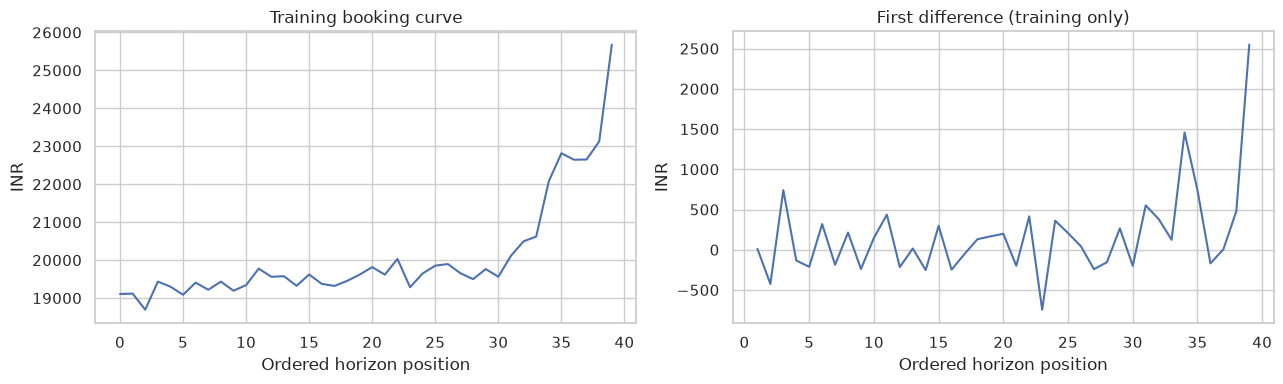

In [ ]:
from statsmodels.tsa.stattools import adfuller
curve = clean.groupby('days_left')['price'].mean().sort_index(ascending=False)
series = curve.reset_index(drop=True)
train_s, test_s = series.iloc[:-9], series.iloc[-9:]
# Do not inspect held-out tail when deciding differencing/order.
p_raw = adfuller(train_s)[1]
p_diff = adfuller(train_s.diff().dropna())[1]
d = 0 if p_raw < .05 else 1
print('points:', len(series), '| training:', len(train_s), '| held out:', len(test_s))
print('Training-only ADF p-values:', {'raw': p_raw, 'first_difference': p_diff}, '| chosen d:', d)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
train_s.plot(ax=axes[0], title='Training booking curve')
train_s.diff().dropna().plot(ax=axes[1], title='First difference (training only)')
for ax in axes: ax.set_xlabel('Ordered horizon position'); ax.set_ylabel('INR')
plt.tight_layout(); plt.show()

/home/sahith/fall2026-american-airlines/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/home/sahith/fall2026-american-airlines/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


,order,AIC,converged
0,"(2, 1, 2)",611.682198,True
1,"(1, 1, 0)",609.340382,True
2,"(0, 1, 1)",609.342017,True
3,"(3, 1, 1)",611.465468,True


                               SARIMAX Results                                
Dep. Variable:                  price   No. Observations:                   40
Model:                 ARIMA(1, 1, 0)   Log Likelihood                -302.670
Date:                Tue, 03 Nov 2026   AIC                            609.340
Time:                        20:38:30   BIC                            612.668
Sample:                             0   HQIC                           610.534
                                 - 40                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0393      0.226      0.174      0.862      -0.403       0.482
sigma2      3.212e+05    4.2e+04      7.655      0.000    2.39e+05    4.03e+05
Ljung-Box (L1) (Q):                   0.01   Jarque-

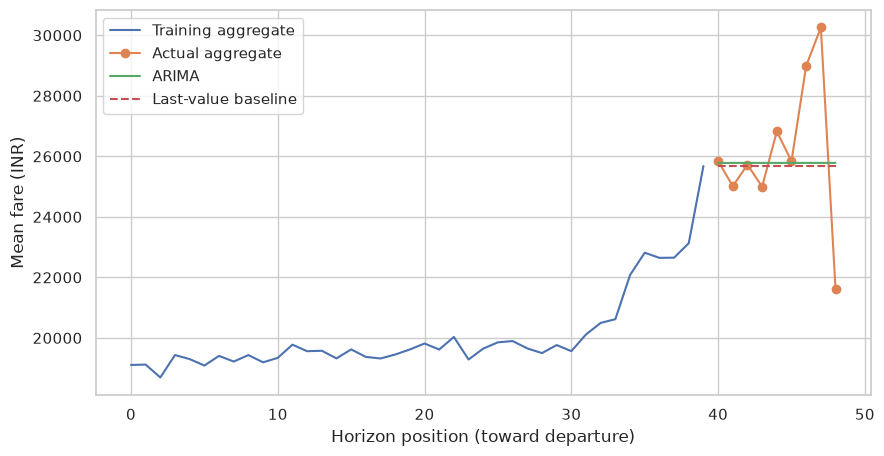

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
arima_candidates, arima_rows = {}, []
t0 = time.perf_counter()
for order in [(2, d, 2), (1, d, 0), (0, d, 1), (3, d, 1)]:
    candidate = ARIMA(train_s, order=order).fit()
    converged = bool(candidate.mle_retvals.get('converged', False))
    arima_candidates[order] = candidate
    arima_rows.append({'order': order, 'AIC': candidate.aic, 'converged': converged})
arima_table = pd.DataFrame(arima_rows)
display(arima_table)
eligible = arima_table[arima_table.converged]
if eligible.empty:
    raise RuntimeError('No ARIMA candidate converged; revise training-only candidates.')
best_order = eligible.sort_values('AIC').iloc[0]['order']
arima = arima_candidates[best_order]
arima_seconds = time.perf_counter() - t0
print(arima.summary())
fc = arima.forecast(steps=len(test_s))
naive = np.repeat(train_s.iloc[-1], len(test_s))
arima_mae = mean_absolute_error(test_s, fc)
naive_mae = mean_absolute_error(test_s, naive)
print('Selected order:', best_order, '| ARIMA MAE:', arima_mae, '| naive MAE:', naive_mae)
print('ARIMA order search seconds:', arima_seconds)
plt.plot(train_s.index, train_s, label='Training aggregate')
plt.plot(test_s.index, test_s, marker='o', label='Actual aggregate')
plt.plot(test_s.index, np.asarray(fc), label='ARIMA')
plt.plot(test_s.index, naive, ls='--', label='Last-value baseline')
plt.xlabel('Horizon position (toward departure)'); plt.ylabel('Mean fare (INR)')
plt.legend(); plt.show()

**ARIMA — verdict.** Training-AIC selection chose ARIMA(1,1,0), whose held-out aggregate MAE was ₹1,626.03 versus ₹1,647.26 for the naive last-value baseline: an improvement of only ₹21.23, about 1.3%. The training-only ADF p-values were 1.0000 before differencing and 0.9696 afterward, so neither test rejects a unit root; differencing once is an exploratory choice here, not a demonstrated fix for stationarity. With only 40 training points, that weak diagnostic evidence and the tiny baseline gain prevent a strong forecasting claim. This model extends the mean fare curve over the final nine booking horizons; it does not price an individual ticket or forecast actual calendar dates. Aggregation discards ticket-level airline, cabin, route, stops and fare dispersion, and the horizon means pool different flights rather than follow one cohort over time. A revenue analyst could use this as a descriptive aggregate exercise, but I would not include this ARIMA as an operational American Airlines forecast without dated, regularly sampled and product-consistent observations. It could later sit alongside a ticket model for a separate aggregate forecasting question, with its own baseline and prospective validation.

> **For the curious: SARIMAX.** The `statsmodels` family does extend to seasonality and features: `SARIMAX` adds a seasonal component and an `exog=` argument for external regressors. With real departure dates you could model weekly and holiday seasonality and feed in fuel price or capacity — which is much closer to how an airline forecasts demand. We cannot, because this dataset has no dates. Worth knowing the door exists.

### 6c — Model-selection decision table

Measured on the same 80,000 training rows and 59,588 test rows, except ARIMA's separate aggregate target. Times include preprocessing and fitting and are specific to this machine. Ridge/Lasso rows use inner-validation-selected alpha, rather than cherry-picking the final test split.

| Model | Reported MAE (INR) | R² | Fit time | Interpretable? | When would I choose it? |
|---|---|---|---|---|---|
| Dummy (mean) | 19,784.15 | approximately 0 | 0.14 s | Constant mean | As the minimum reference for feature value. |
| Ridge, alpha 100 | 4,516.10 | 0.9091 | 0.15 s | Conditional coefficients | Fast, explainable baseline when a client needs readable effects. |
| Lasso, alpha 0.001 | 4,516.64 | 0.9091 | 0.34 s | Conditional coefficients; higher alpha yields sparsity | When reducing the feature list matters; alpha 100 zeroed three terms with MAE 4,462.86 but was an illustrative fit, not the validation-selected setting. |
| Random Forest | 1,476.83 | 0.9825 | 6.64 s | No simple coefficient explanation | Individual-ticket prototype with nonlinear interactions and manageable training cost. |
| XGBoost | 2,024.10 | 0.9755 | 1.70 s | No simple coefficient explanation | Faster reruns or later objective/capacity experiments when boosting tuning is feasible. |
| ARIMA(1,1,0) | n/a for tickets; aggregate MAE 1,626.03 | n/a | 0.52 s across four candidate orders | Partly | Only as a separate horizon-aggregate exercise; naive aggregate MAE was 1,647.26. |

**Choice: Random Forest for a research prototype, with three reasons beyond accuracy.** (1) It represents the nonlinear booking curve and cabin/route interactions without manually specifying a global linear equation. (2) Bagging has a simpler tuning story for a teammate than interacting learning-rate/boosting-depth/round-count settings. (3) A depth-20, 100-tree fit took under seven seconds on this sample, a practical cost for reproducible iteration here. Its strongest drawbacks are limited interpretability and potentially greater memory and prediction cost; those costs must be measured before production deployment. The better held-out MAE supports the choice, but it is not its only justification.

---
# Section 7 — Defend your choice

### 7a — The full scoreboard

**PM summary:** Random Forest had the lowest comparable holdout MAE, ₹1,477, versus ₹19,784 for the dummy. Training-only five-fold CV on the fixed 80,000-row sample gave MAE ₹1,536 ± ₹17 and R² 0.9819 ± 0.0007. Each CV fold uses 64,000 training rows; the ± value is fold standard deviation, not a confidence interval for the holdout score.


In [ ]:
scoreboard = show_scoreboard().sort_values('MAE')
display(scoreboard)
# Validate the selected model on training-only folds; do not reuse test rows.
rf_cv = cross_validate(fitted['RandomForest'], X_fit, y_fit, cv=cv,
    scoring=['r2', 'neg_mean_absolute_error'], n_jobs=1)
rf_cv_mae = -rf_cv['test_neg_mean_absolute_error']
print(f'Best comparable ticket model: Random Forest, test MAE INR '
      f'{scoreboard.loc["RandomForest", "MAE"]:,.0f}; training-only 5-fold CV MAE INR '
      f'{rf_cv_mae.mean():,.0f} ± {rf_cv_mae.std(ddof=1):,.0f}; '
      f'dummy test MAE INR {scoreboard.loc["Dummy (mean)", "MAE"]:,.0f}.')
print('Random Forest CV R²:', rf_cv['test_r2'].mean(), '±', rf_cv['test_r2'].std(ddof=1))
print('CV folds train on 64,000 rows, final comparison models on 80,000; '
      'fold std is not a confidence interval for test MAE.')

,MAE,RMSE,R2,MAPE%,fit_seconds,training_rows
model,,,,,,
RandomForest,1476.8283,2995.7825,0.9825,10.9333,4.4672,80000.0
D1 baseline (3 leaks),1926.8089,3379.2592,0.9778,14.4221,NaN,NaN
"XGBoost (honest, full training)",1990.2113,3500.5308,0.9761,14.3995,3.8023,NaN
XGBoost,2024.0961,3545.2333,0.9755,14.6258,0.8327,80000.0
MSE (XGBoost),2038.6838,3573.9138,0.9751,14.6946,0.8667,80000.0
MAE (XGBoost),2073.6494,4072.7765,0.9677,13.5614,0.8875,80000.0
no row counter,2096.7662,3665.6117,0.9739,14.9389,1.2903,NaN
no counter + deduped,2108.4547,3648.2677,0.9741,15.2509,1.4006,NaN
Huber (sklearn GBR),2366.2521,4282.4573,0.9643,16.1207,19.3548,80000.0


Best comparable ticket model: Random Forest, test MAE INR 1,477; training-only 5-fold CV MAE INR 1,536 ± 17; dummy test MAE INR 19,784.
Random Forest CV R²: 0.9819247636366448 ± 0.000696436345989209
CV folds train on 64,000 rows, final comparison models on 80,000; fold std is not a confidence interval for test MAE.


### 7b — What this means for American Airlines

We are modelling **Indian domestic fares scraped from EaseMyTrip in 2022**. American Airlines is a different carrier in a different market in a different year. Be precise about what transfers.

**What transfers — the structure of the problem and the method.** Airline revenue management has the same shape everywhere: fares move with the booking horizon, cabin class dominates price, route density and competition set the base level, and time-of-day and connections differentiate the product. Your model-selection reasoning transfers completely: tree ensembles for per-ticket prediction, asymmetric loss where over- and under-pricing cost differently, a time-series model for forecasting an aggregate curve through real time.

**What does not transfer:** nearly all the specifics. Different regulatory regime, competitive set, cost base, currency, and demand seasonality — and 2022 was still distorted by post-pandemic recovery.

**What the dataset is missing that real pricing requires:**

| Missing | Why it matters |
|---|---|
| **Seat inventory / load factor** | Revenue management is fundamentally about *remaining seats*. We have no capacity data at all — the largest single gap. |
| **Departure dates** | We have `days_left` but not *when*. No seasonality, no holidays, no day-of-week. **This is also precisely why ARIMA had so little to work with.** |
| **Competitor fares** | Fares are set against what everyone else charges on the route, in near-real-time. |
| **Fare class / fare basis** | "Economy" spans a dozen booking classes with different prices and restrictions; our `class` flattens all of it to two values. |
| **Demand signals** | Searches, booking pace, events — the leading indicators pricing teams actually watch. |

### 7c — Reflection

Answer each in the cell below it, in your own words. A PM will ask these in your PR review, so treat it as practice for that conversation.

---

**Q1 — The honest number.** You produced several R² values for the same task. List them with one line each on what changed, then name the single number you would put in front of American Airlines and defend it in two sentences.

**Answer Q1:** The D1 reproduction scored R² 0.9778 with the counter, duplicates and full-data encoders; dropping the counter gave 0.9739; also deduplicating gave 0.9741; the full-training pipeline with deliberate one-hot/ordinal encoding gave 0.9761. The encoding change means the last step does more than eliminate full-data fitting, so it is not a pure estimate of encoder leakage. Training-only XGBoost five-fold CV gave 0.9755 ± 0.0008 on the 80,000-row sample. In the separate fair model-family comparison, Random Forest reached holdout R² 0.9825 with MAE ₹1,477 and training-only CV R² 0.9819 ± 0.0007 (MAE ₹1,536 ± ₹17). The single leading score I would report for the selected prototype is Random Forest holdout MAE ₹1,477, accompanied by its R², sample size, CV variability and evaluation design. I would clearly label it an Indian-fares random-split benchmark rather than a validated American Airlines performance forecast, because market differences, missing dates and repeated flight identities limit what this split establishes.


**Q2 — Model family.** You would ship one of Ridge / Lasso / Random Forest / XGBoost. Name it, and give **three** reasons that are not "it had the best score" — e.g. fit time, tuning burden, interpretability, robustness, what the stakeholder needs. Then name the strongest argument *against* your choice.

**Answer Q2:** I would choose the clean, depth-limited Random Forest as the individual-ticket research prototype. First, it can represent the nonlinear booking horizon and cabin/route interactions that a single straight line misses. Second, bagging has fewer interacting tuning choices than boosting, making it easier for a teammate to maintain a stable baseline. Third, bounding depth at 20 and using 100 trees kept this experiment's fit cost practical at 6.64 seconds on the fixed sample. Its MAE advantage supports those reasons but does not replace them. The strongest argument against it is that a forest is harder to explain than Ridge and can have larger prediction-time and memory costs than a compact booster; neither deployment cost was benchmarked here. I would not claim these Indian-market fares establish a production pricing policy for American Airlines.

**Q3 — Lasso vs Ridge.** Explain to a teammate who has not done this deliverable why L1 produces exact zeros and L2 does not. Then say which you would use on this dataset and why — including the possibility that neither penalty mattered much here, and what about this dataset makes that the case.

**Answer Q3:** Lasso's L1 penalty has a corner at zero: if a feature's residual association is small enough, the optimum coefficient can be exactly zero. Ridge's L2 penalty has a smooth derivative proportional to the coefficient, so it generally shrinks a useful coefficient without thresholding it to zero. Both depend on feature units, which is why this notebook standardizes all encoded predictors within the pipeline. I would use Ridge for a stable, explainable linear baseline when correlated predictors should share weight; Lasso is useful when a shorter feature list is the requirement. Neither changes the fact that a straight-line model misses nonlinear cabin, route and booking-horizon interactions. With tens of thousands of observations and only a few dozen encoded features, regularization is less important than it would be with many predictors and few rows.

**Q4 — Loss functions.** Your Deliverable 1 model minimised squared error because that is the default. Having seen the comparison: was that the right default for this data? Which loss would you train on now, and which metric would you report? If those two differ, justify the mismatch.

**Answer Q4:** Squared error was a defensible reference loss, but not an automatically correct business objective. In the matched XGBoost comparison it achieved test MAE ₹2,039 and RMSE ₹3,574, versus MAE ₹2,074 and RMSE ₹4,073 for absolute-error training; absolute-error training did improve MAPE from 14.69% to 13.56%. Thus the expected rule that each loss wins its matching metric did not fully occur, and I would not claim MAE training won MAE here. For a symmetric point-estimation benchmark I would retain a squared-error baseline (the selected Random Forest also uses squared-error splits) and report MAE in rupees alongside RMSE, MAPE and cabin-specific validation before deployment. That loss/metric mismatch is deliberate: squared loss makes large misses costly during fitting, while MAE makes typical absolute error easier for a stakeholder to understand. For the explicitly assumed traveler-facing use case where recommending too high a fare is worse, I would separately test a lower-quantile recommendation such as alpha 0.1, using pinball loss and a validated business cost rather than treating a lower quote as a revenue optimum.

**Q5 — ARIMA and problem shape.** Someone proposes ARIMA for predicting individual ticket prices. Explain in three sentences why that does not work, and what they would need to change about the data or the question for a time-series model to be the right call.

**Answer Q5:** A univariate ARIMA model extrapolates an ordered series from its own past values and errors; it does not accept an unordered ticket's cabin, airline and route as the tabular predictors used here. The booking-curve exercise forecasts nine held-out aggregate horizon means, rather than any individual ticket, and the horizons pool different flights instead of tracking one flight over calendar time. To use time-series modeling operationally, collect dated fare observations on consistent routes/products at regular intervals, or change the task to forecasting a dated aggregate series with appropriate external variables.

**Q6 — Leakage.** Explain leakage to a teammate using an example from your own notebook run (not one from the text). Then name the one habit from this notebook you will carry into Deliverable 3 to prevent it.

**Answer Q6:** Leakage means using information during model development that would be unavailable when predicting an unseen ticket. In this run, the constructed `price_per_hour = price / duration` feature produced R² 0.99955 and MAE about ₹240, because the unknown answer was already hidden inside a predictor. It is invalid regardless of how attractive the metrics look, so that result is explicitly excluded from the model scoreboard and the feature never enters the production feature list. The exported row counter was another artificial signal, ranking second in the D1 importance list. My habit for Deliverable 3 is to keep preprocessing and estimation inside one cross-validated pipeline, and ask for every feature whether its value is actually known at prediction time. Pipelines prevent preprocessing leaks only when fitted within the correct split; they cannot make a target-derived feature safe.

**Q7 — Team git.** Deliverable 1 was `deliverable1/<your-name>` → `main`. Deliverable 2 is `team-##/<your-name>` → `team-##/main` → `main`. What does the extra layer buy a project with 70+ contributors? Then describe something that actually went wrong or felt awkward in your team's git this week — a real friction point is worth more here than a clean answer.

**Answer Q7:** The team trunk gathers related member work and gives teammates a place to review compatibility before one coordinated PR reaches the repository's main branch. With 70+ contributors, that reduces the number of unrelated individual submissions a PM must review directly and keeps the team report aligned with the team's notebooks. A real friction point in this session was confusing local `team-02` (whose old upstream was gone), the current trunk `team-02/main`, and my personal branches `deliverable2/sahith-yamani` and `sahith-yamani`. Checking `git branch --show-current`, `git branch -avv`, and the PR base makes those different roles visible. This notebook belongs on `sahith-yamani`, with a PR into `team-02/main`; creating or renaming a file does not itself merge it into the trunk.

---
## Before you submit — checklist

**The notebook**

1. **Kernel → Restart & Run All.** It must run top-to-bottom with no errors. A notebook that only works in the order you happened to click cells is not reproducible.
2. Every `# TODO` cell is filled in.
3. Every markdown answer prompt has a real answer. An unanswered placeholder left anywhere is an incomplete deliverable.
4. The three summary tables are filled in: the EDA decisions (2e), the model-selection table (6c), and the scoreboard (7a).
5. **Kernel → Restart & Clear Output** before committing. Keeps the diff reviewable and prevents most notebook merge conflicts.

**Git hygiene**

6. `git status` shows **no** `.csv`. If it does, stop — do not commit, and check [`.gitignore`](../.gitignore).
7. You are on your own member branch — not your team's trunk, and definitely not `main`. Check with `git branch --show-current`.

```sh
git add deliverable2/flight_price_modeling_sahith-yamani.ipynb
git commit -m "deliverable2: EDA, leakage fixes, model selection"
git push
```

8. Open a PR from your member branch into **your team's trunk branch**. GitHub defaults the base to `main` — change it by hand.
9. Request review from the teammate assigned to you in [`README.md`](README.md), and **review the PR assigned to you**. Reviewing is half the job.
10. Once every member's PR has merged into the team trunk, the team fills in [`TEAM_REPORT.md`](TEAM_REPORT.md) together and a PM reviews the trunk → `main`.

---

You arrived with one model and one score. You are leaving with five models, four loss functions, an honest number, and — most importantly — a reason for every choice.

In Deliverable 3 we tune the winner: hyperparameter search over the pipeline you built, learning curves to distinguish a data problem from a model problem, and error analysis by segment to find out *where* it fails rather than just how much. 🛫